
# Peramalan Beban Listrik Per Jam Panama: Perbandingan *Foundation Model* Deret Waktu dengan Model Statistik dan *Machine Learning*

**Abstrak.** Penjadwalan pembangkit listrik bergantung pada ramalan beban per jam, sedangkan *foundation model* deret waktu menawarkan peramalan tanpa estimasi parameter pada data lokal. Penelitian ini membandingkan empat konfigurasi *foundation model* yang dijalankan secara *zero-shot* (Chronos-Bolt, Chronos-2 univariat, Chronos-2 dengan kovariat, dan TimesFM 2.0) dengan tiga model statistik (SNaive-168, SARIMAX-W, dan SARIMAX-DHR) serta XGBoost untuk peramalan 24 jam ke depan beban nasional Panama. Evaluasi dilakukan melalui *rolling-origin backtest* dengan 178 origin harian (1 Januari sampai 26 Juni 2020) yang mencakup regime Normal dan regime pembatasan COVID-19. Ukuran yang dipakai adalah MAE, MAPE, MASE, *weighted quantile loss*, dan cakupan interval 80%, disertai uji Diebold-Mariano. Chronos-2 dengan kovariat cuaca dan kalender menghasilkan galat terendah (MAPE 2,79%; MASE 0,564), atau 54% lebih akurat daripada *seasonal naive*. Urutan berikutnya adalah Chronos-2 univariat (2,85%), Chronos-Bolt (3,18%), TimesFM 2.0 (3,22%), XGBoost (4,19%), dan SARIMAX-W (4,44%). Keunggulan Chronos-2 dengan kovariat atas semua model selain Chronos-2 univariat signifikan ($p < 0{,}01$). Manfaat kovariat baru signifikan pada regime COVID-19 ($p = 0{,}033$). Pada regime COVID-19, interval 80% *foundation model* cenderung terlalu sempit (cakupan 69,8% sampai 76,6%). Hasil ini menunjukkan bahwa *foundation model zero-shot* layak dijadikan acuan awal yang kuat untuk peramalan beban jangka pendek, termasuk saat terjadi perubahan struktural, dengan catatan kalibrasi interval perlu diperiksa sebelum dipakai secara operasional.

**Kata kunci:** peramalan beban jangka pendek; *foundation model* deret waktu; Chronos-2; uji Diebold-Mariano; perubahan struktural COVID-19.

**Struktur notebook.** Subbab 1 berisi pendahuluan dan tinjauan *foundation model*. Subbab 2 memuat analisis eksploratif. Subbab 3 menjelaskan metodologi dan implementasi delapan model. Subbab 4 menyajikan hasil. Subbab 5 menjelaskan penyimpanan model. Subbab 6 berisi pembahasan, dan Subbab 7 berisi kesimpulan serta saran. Setiap sel kode memuat satu baris komentar; penjelasan rinci ditempatkan pada sel *markdown*.



## 1. Pendahuluan

### 1.1 Latar belakang

Operator sistem tenaga listrik harus menyeimbangkan pasokan dan permintaan setiap jam. Ramalan beban yang terlalu rendah memaksa pengoperasian pembangkit cadangan berbiaya tinggi, sedangkan ramalan yang terlalu tinggi menimbulkan kapasitas siaga yang tidak terpakai `[RUJUKAN DIPERLUKAN: kuantifikasi biaya kesalahan peramalan beban jangka pendek]`. Karena itu, peramalan beban jangka pendek (*short-term load forecasting*, STLF) menjadi salah satu masalah peramalan deret waktu yang paling banyak dikaji.

Data yang dianalisis adalah beban listrik nasional Panama per jam yang dipublikasikan oleh Aguilar Madrid dan Antonio (2021) beserta dataset pendampingnya di Mendeley Data. Dalam studi tersebut, pusat dispatch nasional Panama (CND) menghasilkan ramalan mingguan dan para penulis mengembangkan model *machine learning* untuk horizon 168 jam. Dataset memuat beban nasional, variabel cuaca dari tiga kota (Tocumen/Kota Panama, Santiago, dan David), serta indikator hari libur dan masa sekolah.

Dalam beberapa tahun terakhir muncul kelas model baru, yaitu *foundation model* deret waktu: jaringan *transformer* yang dilatih sekali pada korpus deret waktu lintas domain berukuran sangat besar, lalu dipakai untuk meramal deret baru tanpa pelatihan ulang (*zero-shot*). Contohnya Chronos (Ansari dkk., 2024), Chronos-2 (Ansari dkk., 2025), TimesFM (Das dkk., 2024), Moirai (Woo dkk., 2024), Lag-Llama (Rasul dkk., 2023), dan TimeGPT (Garza dkk., 2023). Bagi analis statistik muncul pertanyaan praktis: apakah model tanpa estimasi parameter pada data lokal ini mampu menyaingi model yang dibangun khusus dengan pengetahuan domain (musiman ganda, cuaca, dan kalender)?

Data Panama juga memuat ujian ketangguhan yang alami. Mulai pekan ketiga Maret 2020, pembatasan aktivitas akibat COVID-19 menurunkan rata-rata beban mingguan dari sekitar 1.300 MWh menjadi sekitar 1.020 sampai 1.110 MWh (dihitung dari data ini). Perubahan struktural semacam ini tidak pernah dilihat model selama pelatihan, sehingga periode tersebut menguji kemampuan adaptasi tiap pendekatan.

### 1.2 Rumusan masalah

1. Bagaimana karakteristik deret beban listrik Panama, yaitu tren, musiman harian dan mingguan, serta pengaruh cuaca dan kalender?
2. Seberapa akurat *foundation model* (Chronos-Bolt, Chronos-2, dan TimesFM) secara *zero-shot* dibandingkan model statistik (*seasonal naive*, SARIMAX pada beda musiman mingguan, dan regresi harmonik dinamis) serta model *machine learning* (XGBoost) untuk peramalan 24 jam ke depan?
3. Apakah penambahan kovariat cuaca dan kalender pada Chronos-2 meningkatkan akurasi?
4. Bagaimana kinerja setiap model pada periode perubahan struktural COVID-19?
5. Apakah perbedaan akurasi antarmodel signifikan secara statistik menurut uji Diebold-Mariano?

### 1.3 Tujuan

Penelitian ini bertujuan (a) mendeskripsikan pola beban listrik Panama, (b) membandingkan akurasi titik dan akurasi probabilistik delapan model peramalan melalui *backtest* bergulir, (c) mengukur kontribusi kovariat pada *foundation model*, dan (d) menguji signifikansi perbedaan akurasi.

### 1.4 Batasan

- Horizon peramalan 24 jam (*day-ahead*) dengan titik asal (*origin*) setiap pukul 00.00, sebanyak 178 origin dari 1 Januari sampai 26 Juni 2020.
- Kovariat cuaca memakai nilai observasi, bukan ramalan cuaca. Akurasi model yang memakai cuaca (SARIMAX-W, SARIMAX-DHR, XGBoost, Chronos-2+Kov) karenanya merupakan batas atas (*oracle*); dalam operasi nyata, galat ramalan cuaca akan menambah galat beban.
- *Foundation model* dijalankan *zero-shot* di CPU tanpa *fine-tuning*.
- Moirai, Lag-Llama, dan TimeGPT tidak dijalankan karena alasan teknis yang dijelaskan pada Subbab 1.5; ketiganya dibahas secara konseptual.



### 1.5 *Foundation model* deret waktu: konsep dan posisinya

**Konsep.** *Foundation model* deret waktu adalah model berparameter besar yang dilatih satu kali pada kumpulan deret dari banyak domain (energi, lalu lintas, ekonomi, cuaca, data sintetis), kemudian dipakai langsung pada deret baru. Dari sudut pandang statistika, model ini memperkirakan distribusi prediktif bersyarat

$$p\left(y_{T+1:T+H} \mid y_{T-C+1:T},\; \mathbf{x}\right)$$

secara langsung. Jendela konteks sepanjang $C$ titik berperan sebagai data pengkondisi (*in-context learning*), bukan sebagai data untuk mengestimasi parameter. Pengetahuan tentang bentuk musiman, tren, dan derau yang lazim berasal dari pra-pelatihan, sehingga fungsinya mirip *prior* yang sangat informatif.

**Perbandingan paradigma.**

| Aspek | Statistik klasik (ARIMA, ETS, DHR) | *Machine learning* (XGBoost) | *Foundation model* |
|---|---|---|---|
| Cakupan model | Satu model per deret | Satu model per dataset | Satu model untuk semua deret |
| Estimasi | MLE pada deret itu sendiri | Pelatihan pada data lokal | Tidak ada; hanya inferensi |
| Asumsi | Struktur eksplisit (stasioneritas, orde ARIMA) | Rekayasa fitur oleh analis | Implisit, dipelajari dari korpus |
| Ketidakpastian | Analitik (asumsi Gaussian) | Perlu metode tambahan | Kuantil atau sampel langsung |
| Interpretabilitas | Tinggi (koefisien, uji) | Sedang (kepentingan fitur) | Rendah |

**Model yang dikaji.**

| Model | Pengembang | Arsitektur dan gagasan kunci | Keluaran | Kovariat | Status dalam analisis ini |
|---|---|---|---|---|---|
| Chronos (Ansari dkk., 2024) | Amazon | *Encoder-decoder* keluarga T5; nilai deret diskalakan dan dikuantisasi menjadi token, lalu dilatih seperti model bahasa | Probabilistik (sampel) | Tidak | Diwakili Chronos-Bolt |
| Chronos-Bolt | Amazon | Varian Chronos berbasis *patch* yang langsung menghasilkan kuantil untuk banyak langkah sekaligus (kartu model `amazon/chronos-bolt-small`) | Kuantil 0,1 sampai 0,9 | Tidak | Dijalankan (ukuran *small*) |
| Chronos-2 (Ansari dkk., 2025) | Amazon | Mekanisme *group attention* untuk *in-context learning* lintas target dan kovariat; menangani kasus univariat, multivariat, dan berkovariat | Kuantil | Ya, masa lalu dan masa depan | Dijalankan, tanpa dan dengan kovariat |
| TimesFM (Das dkk., 2024) | Google | *Decoder-only* dengan masukan berupa *patch*; dilatih pada korpus nyata dan sintetis berukuran sekitar 100 miliar titik waktu | Rata-rata dan kuantil | Tidak (versi yang dipakai) | Dijalankan (versi 2.0, 500 juta parameter) |
| Moirai (Woo dkk., 2024) | Salesforce | *Masked-encoder transformer* universal, dilatih pada arsip LOTSA berisi lebih dari 27 miliar observasi; menerima jumlah variat sembarang | Probabilistik (distribusi parametrik) | Ya | Tidak dijalankan: pustaka `uni2ts` mensyaratkan `torch<2.5`, `numpy~=1.26`, dan `scipy~=1.11` sehingga merusak lingkungan yang ada |
| Lag-Llama (Rasul dkk., 2023) | Konsorsium akademik dan industri | *Decoder-only* bergaya LLaMA dengan nilai lag sebagai kovariat; univariat probabilistik | Probabilistik (distribusi parametrik) | Tidak | Tidak dijalankan: bergantung pada GluonTS versi lama dan instalasi dari repositori git |
| TimeGPT (Garza dkk., 2023) | Nixtla | Model sumber tertutup yang diakses melalui API | Titik dan interval | Ya, melalui API | Tidak dijalankan: memerlukan kunci API berbayar dan pengiriman data ke layanan eksternal |

Ketiga model yang tidak dijalankan dapat ditambahkan dengan pola kode yang sama (fungsi yang menerima konteks dan mengembalikan matriks kuantil berukuran origin x horizon x 9), di lingkungan Python terpisah untuk Moirai dan Lag-Llama.


In [1]:
# Pustaka, konfigurasi path, desain backtest, dan gaya grafik
import warnings, json, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import xgboost as xgb
from scipy import stats
from statsmodels.tsa.seasonal import MSTL
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.statespace.sarimax import SARIMAX, SARIMAXResults
from huggingface_hub import snapshot_download
from chronos import BaseChronosPipeline
from transformers import TimesFmModelForPrediction

warnings.filterwarnings('ignore')
np.random.seed(42); torch.manual_seed(42)
DATA = Path('Panama_beban_listrik_per_jam_2015-2020_.xlsx')
MODEL_DIR, OUT, DASH = Path('models'), Path('outputs'), Path('dashboard')
for p in (MODEL_DIR, OUT, DASH):
    p.mkdir(exist_ok=True)
H, CTX = 24, 2048
QS = [i / 10 for i in range(1, 10)]
TEST_START, COVID_START = pd.Timestamp('2020-01-01'), pd.Timestamp('2020-03-15')
MODELS = ['Chronos-2+Kov', 'Chronos-2', 'Chronos-Bolt', 'TimesFM-2.0', 'XGBoost', 'SARIMAX-W', 'SARIMAX-DHR', 'SNaive-168']
COLORS = dict(zip(MODELS, ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#8a8984']))
INK, MUTED, GRID, BLUE_SEQ = '#0b0b0b', '#52514e', '#e4e3df', sns.light_palette('#184f95', as_cmap=True)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.edgecolor': GRID, 'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.6,
                     'axes.labelcolor': MUTED, 'xtick.color': MUTED, 'ytick.color': MUTED, 'axes.titleweight': 'bold',
                     'axes.titlesize': 11, 'axes.titlelocation': 'left', 'lines.linewidth': 1.4, 'font.size': 9.5,
                     'legend.frameon': False})
print('torch', torch.__version__, '| thread CPU:', torch.get_num_threads())

torch 2.8.0+cpu | thread CPU: 6


In [2]:
# Kompatibilitas: scipy >= 1.18 menghapus argumen disp yang masih dikirim statsmodels 0.14.2 ke optimizer L-BFGS
import scipy.optimize as so
if 'disp' not in so.fmin_l_bfgs_b.__code__.co_varnames:
    _lbfgs = so.fmin_l_bfgs_b
    so.fmin_l_bfgs_b = lambda *a, disp=None, **k: _lbfgs(*a, **k)


## 2. Data dan analisis eksploratif

### 2.1 Struktur data

Data terdiri atas 48.048 observasi per jam (3 Januari 2015 pukul 01.00 sampai 27 Juni 2020 pukul 00.00) dalam zona waktu Panama (UTC-05.00). Variabel respons adalah `nat_demand`, yaitu beban listrik nasional (MWh). Variabel penjelas terdiri atas:

- **Cuaca** di tiga kota (akhiran `_toc` untuk Tocumen/Kota Panama, `_san` untuk Santiago, `_dav` untuk David): suhu 2 m (`T2M`), kelembapan 2 m (`QV2M`), presipitasi cair (`TQL`), dan kecepatan angin 2 m (`W2M`).
- **Kalender**: `holiday` (indikator hari libur nasional), `Holiday_ID` (jenis hari libur), dan `school` (indikator masa sekolah).

Lembar `deskripsi` mencatat bahwa satuan kelembapan, presipitasi, dan angin bersumber dari README dataset; nilai `QV2M` yang berkisar 0,01 sampai 0,02 lebih sesuai dengan kelembapan spesifik (kg/kg) daripada kelembapan relatif (%), sehingga satuan tersebut perlu diverifikasi pada sumber aslinya.


In [3]:
# Memuat data, memastikan frekuensi per jam reguler, dan memeriksa nilai hilang
df = pd.read_excel(DATA, sheet_name='data').set_index('datetime').asfreq('h')
y = df['nat_demand']
wcols = [c for c in df.columns if c.split('_')[0] in ('T2M', 'QV2M', 'TQL', 'W2M')]
print(f'Observasi: {len(df):,} | Rentang: {df.index.min()} s.d. {df.index.max()} | Nilai hilang: {df.isna().sum().sum()}')
pd.read_excel(DATA, sheet_name='deskripsi')

Observasi: 48,048 | Rentang: 2015-01-03 01:00:00 s.d. 2020-06-27 00:00:00 | Nilai hilang: 0


,kolom,deskripsi,satuan
0,datetime,"Tanggal-waktu, zona waktu Panama UTC−05:00",tanggal-waktu
1,nat_demand,Beban listrik nasional,MWh
2,T2M_toc,"Suhu pada ketinggian 2 meter di Tocumen, Kota ...",°C
3,QV2M_toc,Kelembapan relatif pada ketinggian 2 meter (me...,% (menurut README)
4,TQL_toc,"Presipitasi cair (menurut README) di Tocumen, ...",l/m² (menurut README)
5,W2M_toc,Kecepatan angin pada ketinggian 2 meter di Toc...,m/s (menurut README)
6,T2M_san,Suhu pada ketinggian 2 meter di Kota Santiago,°C
7,QV2M_san,Kelembapan relatif pada ketinggian 2 meter (me...,% (menurut README)
8,TQL_san,Presipitasi cair (menurut README) di Kota Sant...,l/m² (menurut README)
9,W2M_san,Kecepatan angin pada ketinggian 2 meter di Kot...,m/s (menurut README)


In [4]:
# Statistik deskriptif seluruh variabel
df.describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
nat_demand,48048.0,1182.869,192.069,85.193,1020.057,1168.428,1327.564,1754.882
T2M_toc,48048.0,27.399,1.675,22.953,26.160,27.118,28.558,35.040
QV2M_toc,48048.0,0.018,0.002,0.012,0.017,0.019,0.020,0.023
TQL_toc,48048.0,0.080,0.066,0.000,0.026,0.065,0.117,0.521
W2M_toc,48048.0,13.391,7.296,0.009,7.545,12.182,18.661,39.230
T2M_san,48048.0,26.921,3.018,19.765,24.769,26.167,28.712,39.063
QV2M_san,48048.0,0.018,0.002,0.010,0.017,0.018,0.019,0.022
TQL_san,48048.0,0.106,0.086,0.000,0.037,0.086,0.157,0.485
W2M_san,48048.0,7.047,4.104,0.060,3.955,5.993,9.410,24.484
T2M_dav,48048.0,24.720,2.414,19.934,22.955,24.002,26.243,34.216


In [5]:
# Ringkasan tahunan beban dan laju pertumbuhan rata-rata
yr = y.groupby(y.index.year).agg(['mean', 'std', 'min', 'max', 'count'])
yr['tumbuh_%'] = yr['mean'].pct_change() * 100
yr.round(2)

,mean,std,min,max,count,tumbuh_%
datetime,,,,,,
2015,1131.53,194.15,509.84,1645.48,8711,NaN
2016,1157.19,190.29,744.43,1615.25,8784,2.27
2017,1182.32,188.96,380.59,1635.92,8760,2.17
2018,1205.68,185.45,826.78,1635.54,8760,1.98
2019,1243.58,189.14,85.19,1721.52,8760,3.14
2020,1170.23,176.12,821.85,1754.88,4273,-5.90



### 2.2 Kelengkapan data dan tren tahunan

Data tidak memiliki nilai hilang maupun stempel waktu yang terlewat, sehingga tidak diperlukan imputasi. Rata-rata beban tahunan meningkat dari 1.131,5 MWh (2015) menjadi 1.243,6 MWh (2019) dengan laju pertumbuhan 2,27%, 2,17%, 1,98%, dan 3,14% per tahun. Pertumbuhan yang stabil sekitar 2 sampai 3% per tahun ini menunjukkan tren deterministik yang lemah dibandingkan variasi dalam hari.

Rata-rata 2020 tercatat 5,90% lebih rendah daripada 2019, tetapi angka ini tidak setara dengan laju tahunan lain karena dua alasan. Pertama, data 2020 hanya mencakup Januari sampai Juni. Kedua, periode tersebut memuat pembatasan COVID-19. Perbandingan semester yang setara menunjukkan rata-rata Januari sampai Juni 2020 sebesar 1.170,2 MWh, atau 6,1% di bawah periode yang sama pada 2019 (1.246,8 MWh). Grafik berikut memperlihatkan bahwa penurunan tersebut terkonsentrasi setelah pertengahan Maret 2020.


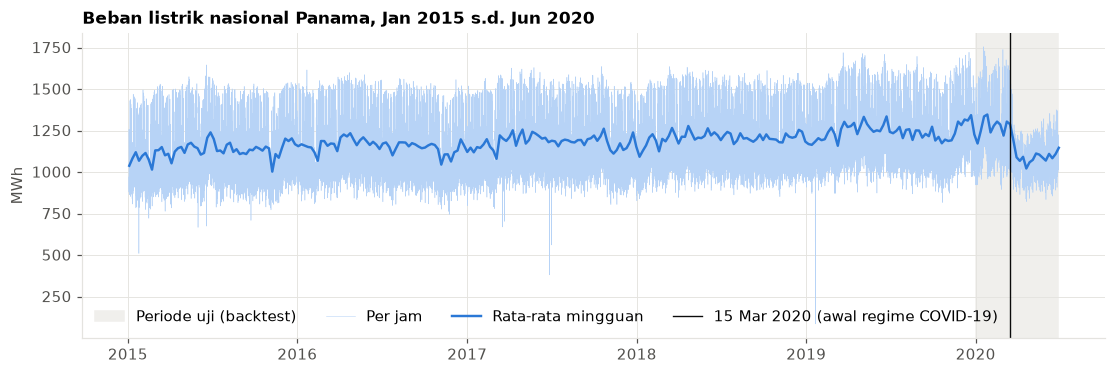

In [6]:
# Deret beban per jam dan rata-rata mingguan, dengan periode uji dan awal pembatasan COVID-19
fig, ax = plt.subplots(figsize=(12, 3.6))
ax.axvspan(TEST_START, y.index[-1], color='#f0efec', zorder=0, label='Periode uji (backtest)')
ax.plot(y.index, y, color='#b7d3f6', lw=0.35, label='Per jam')
ax.plot(y.resample('W').mean(), color='#2a78d6', lw=1.6, label='Rata-rata mingguan')
ax.axvline(COVID_START, color=INK, lw=0.9, ls='-', label='15 Mar 2020 (awal regime COVID-19)')
ax.set(title='Beban listrik nasional Panama, Jan 2015 s.d. Jun 2020', ylabel='MWh')
ax.legend(loc='lower left', ncol=4); plt.show()

In [7]:
# Deteksi anomali: simpangan terhadap median bergulir mingguan melebihi 5 x MAD terskala
dev = y - y.rolling(168, center=True, min_periods=24).median()
mad = 1.4826 * (dev - dev.median()).abs().median()
anom = y[dev.abs() > 5 * mad]
print(f'Titik anomali: {len(anom)} ({len(anom) / len(y):.2%}) | 5 nilai terendah:')
print(y.nsmallest(5).round(1).to_string())
top = anom.groupby(anom.index.date).agg(jumlah_jam='count', beban_min='min').sort_values('jumlah_jam', ascending=False).head(10)
top['hari_libur'] = [int(df.loc[str(d), 'holiday'].max()) for d in top.index]
top.round(1)

Titik anomali: 2 (0.00%) | 5 nilai terendah:
datetime
2019-01-20 12:00:00     85.2
2019-01-20 13:00:00    135.8
2019-01-20 14:00:00    263.6
2017-06-27 12:00:00    380.6
2019-01-20 15:00:00    417.4


,jumlah_jam,beban_min,hari_libur
2019-01-20,2,85.2,0



### 2.3 Perubahan struktural dan anomali

**Perubahan struktural COVID-19.** Rata-rata mingguan pada Februari sampai pertengahan Maret 2020 berada di kisaran 1.220 sampai 1.304 MWh. Setelah pekan 15 Maret 2020, rata-rata mingguan turun ke 1.193 MWh, lalu bertahan pada 1.021 sampai 1.112 MWh hingga akhir Juni. Rata-rata beban pada regime Normal (1 Januari sampai 14 Maret 2020) adalah 1.277,3 MWh, sedangkan pada regime COVID-19 (15 Maret sampai 26 Juni 2020) adalah 1.094,1 MWh, atau turun 14,3%. Perubahan ini berupa pergeseran level yang persisten, bukan pencilan sesaat.

**Anomali titik.** Anomali didefinisikan sebagai simpangan terhadap median bergulir 168 jam yang melebihi 5 kali MAD terskala ($1{,}4826 \times \text{MAD}$). Kriteria ini hanya menandai dua titik, yaitu 20 Januari 2019 pukul 12.00 (85,2 MWh) dan pukul 13.00 (135,8 MWh). Hari tersebut adalah hari Minggu dan bukan hari libur nasional. Beban pulih bertahap pada pukul 14.00 (263,6 MWh) dan 15.00 (417,4 MWh). Pola penurunan mendadak lalu pemulihan bertahap dalam beberapa jam lebih konsisten dengan gangguan pasokan atau kesalahan pencatatan daripada perubahan perilaku konsumen `[RUJUKAN DIPERLUKAN: konfirmasi gangguan sistem 20 Januari 2019 dari laporan operator CND Panama]`. Nilai rendah lain yang tidak melewati ambang adalah 27 Juni 2017 pukul 12.00 (380,6 MWh).

Anomali tersebut tidak dikoreksi karena jumlahnya sangat kecil (kurang dari 0,01% observasi) dan berada di luar periode uji. Pada model yang diestimasi dengan data 2019 (SARIMAX-DHR dan SARIMAX-W), titik ini dapat sedikit memperbesar estimasi $\sigma^2$. Metode median bergulir sengaja tidak menandai penurunan COVID-19, karena median beradaptasi terhadap pergeseran level dalam satu minggu. Dengan demikian, kedua jenis perubahan dibedakan: anomali titik (gangguan sesaat) dan perubahan struktural (perubahan regime).


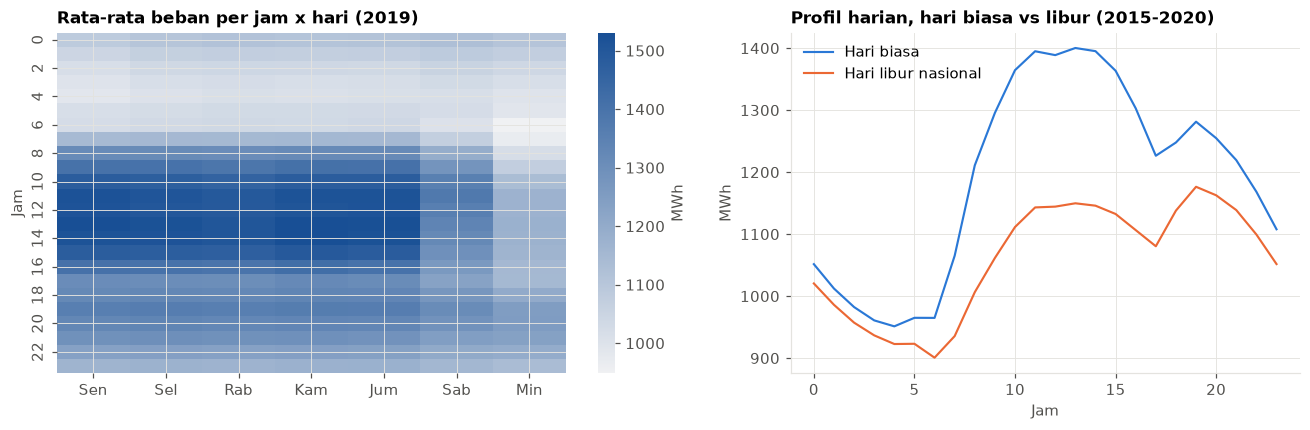

Hari kerja: rerata libur 1069.3 vs biasa 1226.0 MWh | Welch t = -16.11, p = 3.99e-28
Rasio puncak/lembah profil 2019: 1.61


In [8]:
# Profil musiman: rata-rata beban per jam x hari (2019) dan profil harian hari biasa vs libur
d19 = df.loc['2019']
prof = d19.pivot_table(index=d19.index.hour, columns=d19.index.dayofweek, values='nat_demand', aggfunc='mean')
prof.columns = ['Sen', 'Sel', 'Rab', 'Kam', 'Jum', 'Sab', 'Min']
hol = df.groupby([df.index.hour, 'holiday'])['nat_demand'].mean().unstack()
fig, axes = plt.subplots(1, 2, figsize=(12, 4), gridspec_kw={'width_ratios': [1.25, 1]})
sns.heatmap(prof, cmap=BLUE_SEQ, ax=axes[0], cbar_kws={'label': 'MWh'})
axes[0].set(title='Rata-rata beban per jam x hari (2019)', xlabel='', ylabel='Jam')
axes[1].plot(hol.index, hol[0], color=COLORS['Chronos-2+Kov'], label='Hari biasa')
axes[1].plot(hol.index, hol[1], color=COLORS['Chronos-2'], label='Hari libur nasional')
axes[1].set(title='Profil harian, hari biasa vs libur (2015-2020)', xlabel='Jam', ylabel='MWh'); axes[1].legend()
plt.tight_layout(); plt.show()
dd = df.resample('D').agg({'nat_demand': 'mean', 'holiday': 'max'})
dd = dd[dd.index.dayofweek < 5]
t = stats.ttest_ind(dd.loc[dd.holiday == 1, 'nat_demand'], dd.loc[dd.holiday == 0, 'nat_demand'], equal_var=False)
print(f'Hari kerja: rerata libur {dd.loc[dd.holiday == 1, "nat_demand"].mean():.1f} vs biasa {dd.loc[dd.holiday == 0, "nat_demand"].mean():.1f} MWh | Welch t = {t.statistic:.2f}, p = {t.pvalue:.2e}')
print(f'Rasio puncak/lembah profil 2019: {prof.values.max() / prof.values.min():.2f}')


### 2.4 Musiman harian, musiman mingguan, dan efek hari libur

Peta panas 2019 memperlihatkan dua pola musiman yang saling bertumpuk:

- **Musiman harian.** Pada hari kerja, beban terendah terjadi sekitar pukul 04.00 dan puncaknya sekitar pukul 13.00. Nilai tertinggi rata-rata jam x hari adalah 1.531,5 MWh (Kamis pukul 13.00), sedangkan nilai terendahnya 949,2 MWh (Minggu pukul 06.00). Rasio puncak terhadap lembah sebesar 1,61 berarti beban siang hari sekitar 61% lebih tinggi daripada dini hari. Puncak siang hari, bukan malam hari, merupakan ciri sistem tropis dengan beban pendingin ruangan dan aktivitas komersial yang dominan `[RUJUKAN DIPERLUKAN: karakteristik kurva beban harian negara tropis]`.
- **Musiman mingguan.** Rata-rata Senin sampai Jumat relatif setara (1.271,5 sampai 1.281,6 MWh). Rata-rata turun menjadi 1.205,6 MWh pada Sabtu (sekitar 5,5% lebih rendah) dan 1.118,0 MWh pada Minggu (sekitar 12,3% lebih rendah).

**Efek hari libur.** Pada hari kerja, rata-rata beban harian saat libur nasional adalah 1.069,3 MWh, sedangkan pada hari biasa 1.226,0 MWh. Selisih sekitar 157 MWh (12,8%) signifikan menurut uji *t* Welch ($t = -16{,}11$; $p = 3{,}99 \times 10^{-28}$). Profil harian hari libur juga lebih datar dan menyerupai profil hari Minggu. Temuan ini menjadi dasar untuk memasukkan indikator `holiday` ke model yang menerima kovariat. Tanpa informasi ini, model yang hanya membaca pola minggu lalu (misalnya SNaive-168) akan keliru pada hari libur dan juga pada hari kerja tepat satu minggu setelahnya.


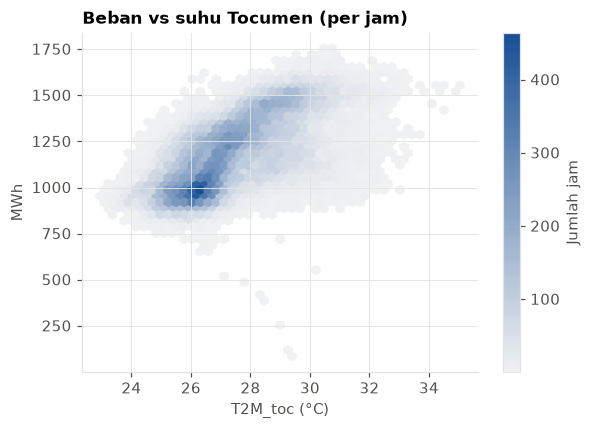

,r_per_jam,r_harian
T2M_toc,0.653,0.153
T2M_dav,0.648,0.140
T2M_san,0.627,0.112
W2M_san,0.192,-0.041
TQL_san,0.119,-0.125
W2M_toc,0.098,-0.007
TQL_toc,0.073,-0.165
TQL_dav,0.042,-0.096
QV2M_san,0.022,0.048
QV2M_dav,-0.002,0.066


In [9]:
# Hubungan beban dengan cuaca: korelasi Pearson pada skala per jam dan rata-rata harian
daily = df.resample('D').mean()
corr = pd.DataFrame({'r_per_jam': df[wcols].corrwith(y), 'r_harian': daily[wcols].corrwith(daily['nat_demand'])})
fig, ax = plt.subplots(figsize=(5.8, 4))
hb = ax.hexbin(df['T2M_toc'], y, gridsize=45, cmap=BLUE_SEQ, mincnt=1)
ax.set(title='Beban vs suhu Tocumen (per jam)', xlabel='T2M_toc (°C)', ylabel='MWh'); fig.colorbar(hb, label='Jumlah jam')
plt.show()
corr.sort_values('r_per_jam', ascending=False).round(3)


### 2.5 Hubungan beban dengan cuaca

Korelasi Pearson antara beban dan suhu pada skala per jam cukup kuat ($r = 0{,}653$ untuk Tocumen, $0{,}648$ untuk David, $0{,}627$ untuk Santiago). Pada skala rata-rata harian, korelasi tersebut turun drastis menjadi $0{,}153$, $0{,}140$, dan $0{,}112$. Perbedaan ini menunjukkan bahwa korelasi per jam sebagian besar merupakan korelasi palsu (*spurious*) akibat siklus harian bersama: suhu dan beban sama-sama naik pada siang hari. Faktor pengacau (*confounder*) dalam hal ini adalah jam dalam sehari, bukan pengaruh suhu terhadap beban.

Penjelasan kedua bersifat klimatologis. Variasi suhu antarhari di Panama kecil: simpangan baku rata-rata harian suhu Tocumen hanya 0,69 °C, sedangkan simpangan baku per jam 1,68 °C. Dengan rentang yang sempit, efek suhu terhadap beban harian sulit dibedakan dari derau. Implikasinya, kontribusi cuaca untuk peramalan 24 jam diperkirakan moderat dan terutama bekerja melalui deviasi suhu di dalam hari terhadap pola musimannya. Dugaan ini diuji secara langsung pada Subbab 4 melalui perbandingan Chronos-2 dengan dan tanpa kovariat, serta melalui koefisien suhu pada SARIMAX-DHR.


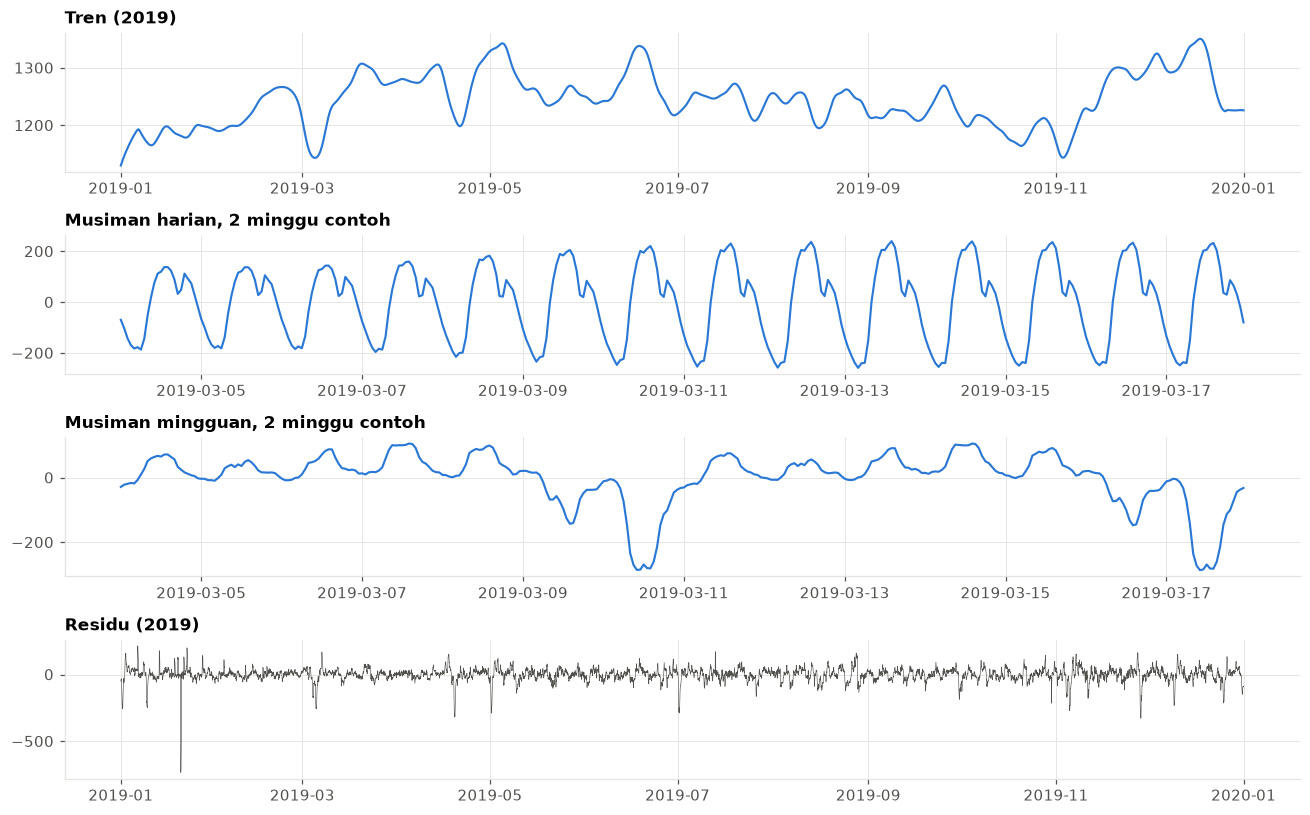

,kekuatan (0-1)
Tren,0.502
seasonal_24,0.906
seasonal_168,0.712


In [10]:
# Dekomposisi MSTL (periode 24 dan 168 jam) pada 2019 dan indeks kekuatan komponen
m = MSTL(y['2019'], periods=(24, 168)).fit()
R = m.resid
strength = {'Tren': 1 - R.var() / (m.trend + R).var()}
strength.update({c: 1 - R.var() / (m.seasonal[c] + R).var() for c in m.seasonal.columns})
fig, axes = plt.subplots(4, 1, figsize=(12, 7.5), sharex=False)
axes[0].plot(m.trend, color='#2a78d6'); axes[0].set_title('Tren (2019)')
wk = slice('2019-03-04', '2019-03-17')
axes[1].plot(m.seasonal['seasonal_24'][wk], color='#2a78d6'); axes[1].set_title('Musiman harian, 2 minggu contoh')
axes[2].plot(m.seasonal['seasonal_168'][wk], color='#2a78d6'); axes[2].set_title('Musiman mingguan, 2 minggu contoh')
axes[3].plot(R, color=MUTED, lw=0.4); axes[3].set_title('Residu (2019)')
plt.tight_layout(); plt.show()
pd.Series(strength).clip(lower=0).round(3).rename('kekuatan (0-1)').to_frame()

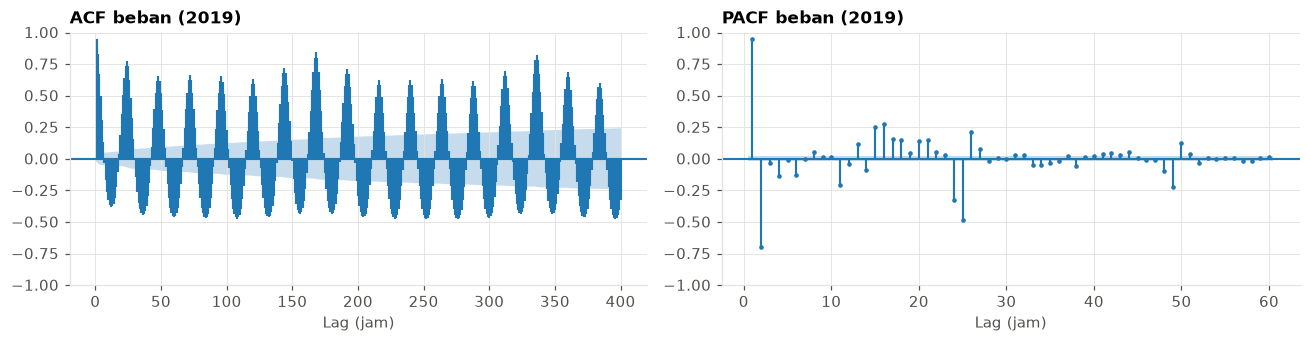

In [11]:
# ACF hingga lag 400 jam dan PACF hingga lag 60 jam (data 2019)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.2))
plot_acf(y['2019'], lags=400, ax=axes[0], zero=False, markersize=0, title='ACF beban (2019)')
plot_pacf(y['2019'], lags=60, ax=axes[1], zero=False, markersize=2, method='ywm', title='PACF beban (2019)')
for a in axes:
    a.set_xlabel('Lag (jam)')
plt.tight_layout(); plt.show()

In [12]:
# Uji stasioneritas ADF (H0: akar unit) dan KPSS (H0: stasioner) pada rata-rata harian
yd = y.resample('D').mean()
rows = []
for nama, s in [('Level harian', yd), ('Beda pertama harian', yd.diff().dropna())]:
    a, k = adfuller(s, autolag='AIC'), kpss(s, regression='c', nlags='auto')
    rows.append([nama, a[0], a[1], k[0], k[1]])
pd.DataFrame(rows, columns=['Deret', 'ADF stat', 'ADF p', 'KPSS stat', 'KPSS p (batas 0,01-0,1)']).round(4)

,Deret,ADF stat,ADF p,KPSS stat,"KPSS p (batas 0,01-0,1)"
0,Level harian,-3.5594,0.0066,3.0714,0.01
1,Beda pertama harian,-14.8039,0.0000,0.0542,0.10



### 2.6 Dekomposisi, autokorelasi, dan stasioneritas

**Dekomposisi MSTL.** Indeks kekuatan komponen $F = \max\{0,\, 1 - \operatorname{Var}(R_t)/\operatorname{Var}(S_t + R_t)\}$ bernilai 0,906 untuk musiman harian, 0,712 untuk musiman mingguan, dan 0,502 untuk tren (data 2019). Musiman harian merupakan sumber variasi paling dominan, diikuti musiman mingguan. Komponen tren dalam satu tahun relatif lemah, sejalan dengan pertumbuhan tahunan 2 sampai 3%.

**Autokorelasi.** ACF bernilai 0,949 pada lag 1, negatif pada lag 12 ($-0{,}381$, fase berlawanan dalam siklus harian), lalu kembali tinggi pada lag 24 (0,777), lag 168 (0,843), dan lag 336 (0,823). Nilai ACF pada lag 168 lebih tinggi daripada lag 24 dan lag 48 (0,658). Hal ini menegaskan bahwa minggu lalu pada jam yang sama merupakan prediktor yang lebih baik daripada kemarin, sehingga *seasonal naive* mingguan menjadi acuan yang wajar. PACF didominasi lag 1 (0,95) dan lag 2 ($-0{,}70$), dengan lonjakan di sekitar lag 24 sampai 26 dan lag 49. Pola ini mendukung komponen AR orde 2 ditambah komponen AR musiman 24 jam, yaitu struktur yang dipakai pada SARIMAX-W.

**Stasioneritas.** Kedua uji pada rata-rata harian memberikan kesimpulan yang bertentangan. Uji ADF menolak hipotesis akar unit (statistik $-3{,}559$; $p = 0{,}0066$), sedangkan uji KPSS juga menolak hipotesis stasioneritas (statistik 3,07; $p \le 0{,}01$). Konflik seperti ini lazim terjadi pada deret yang memiliki tren deterministik atau perubahan struktural, dalam hal ini pergeseran level COVID-19 pada akhir sampel. Setelah pembedaan pertama, kedua uji sepakat bahwa deret stasioner (ADF $p \approx 0$; KPSS $p = 0{,}10$). Hasil ini menjadi dasar penggunaan pembedaan pada model statistik: $d = 1$ pada galat SARIMAX-DHR dan pembedaan musiman 168 jam pada SARIMAX-W.



## 3. Metodologi

### 3.1 Desain evaluasi: *rolling-origin backtest*

Evaluasi dilakukan dengan *backtest* bergulir. Setiap hari pukul 00.00 (origin $T$), setiap model hanya melihat data hingga $T$ lalu meramal $y_{T+1}, \dots, y_{T+24}$. Origin bergeser satu hari dari 1 Januari sampai 26 Juni 2020, sehingga diperoleh 178 origin x 24 jam = 4.272 pasangan ramalan-aktual per model. Origin dibagi menjadi dua regime:

- **Normal**: origin 1 Januari sampai 14 Maret 2020 (74 hari).
- **COVID-19**: origin 15 Maret sampai 26 Juni 2020 (104 hari).

Model yang memerlukan estimasi (SARIMAX-W, SARIMAX-DHR, dan XGBoost) hanya dilatih dengan data sebelum 1 Januari 2020 dan tidak dilatih ulang selama periode uji. *Foundation model* menerima konteks 2.048 jam terakhir (sekitar 85 hari) pada setiap origin. Desain ini memberikan perbandingan yang adil: semua model memakai informasi yang sama-sama tersedia pada waktu $T$.

### 3.2 Model

**(1) *Seasonal naive* mingguan (SNaive-168)** sebagai acuan minimum:
$$\hat{y}_{T+h} = y_{T+h-168}.$$

**(2) Regresi harmonik dinamis dengan galat ARIMA (SARIMAX-DHR).** Musiman ganda dimodelkan dengan suku Fourier, sedangkan autokorelasi sisa ditangkap oleh galat ARIMA(2,1,1):
$$y_t = \sum_{k=1}^{5}\left[a_k \sin\tfrac{2\pi k t}{24} + b_k \cos\tfrac{2\pi k t}{24}\right] + \sum_{k=1}^{5}\left[c_k \sin\tfrac{2\pi k t}{168} + d_k \cos\tfrac{2\pi k t}{168}\right] + \boldsymbol{\gamma}^\top \mathbf{x}_t + u_t,$$
$$(1-\phi_1 B-\phi_2 B^2)(1-B)\,u_t = (1+\theta_1 B)\,\varepsilon_t,\qquad \varepsilon_t \sim N(0,\sigma^2),$$
dengan $\mathbf{x}_t$ berisi suhu tiga kota, `holiday`, dan `school`. Pendekatan ini dipilih karena SARIMA biasa dengan periode musiman 168 tidak praktis diestimasi. Parameter diestimasi dengan MLE pada data 2019. Pada setiap origin, filter Kalman dijalankan pada 28 hari terakhir dengan parameter tetap (`apply`), lalu ramalan dan variansnya dihitung secara analitik. Kuantil ke-$\tau$ diperoleh dari $\hat{y}_{T+h} + z_\tau \hat{\sigma}_{T+h}$.

**(3) SARIMAX pada beda musiman mingguan (SARIMAX-W).** Pola musiman tidak dimodelkan secara deterministik, melainkan dihilangkan dengan pembedaan musiman $z_t = y_t - y_{t-168}$ (operator $1-B^{168}$). Deret $z_t$ dimodelkan sebagai regresi dengan galat ARIMA(2,0,1)(1,0,0)$_{24}$:
$$z_t = \boldsymbol{\delta}^\top \Delta_{168}\mathbf{x}_t + v_t,\qquad (1-\phi_1 B-\phi_2 B^2)(1-\Phi_1 B^{24})\,v_t = (1+\theta_1 B)\,\varepsilon_t,$$
dengan $\Delta_{168}\mathbf{x}_t = \mathbf{x}_t - \mathbf{x}_{t-168}$ untuk suhu tiga kota, `holiday`, dan `school`. Ramalan beban diperoleh kembali melalui $\hat{y}_{T+h} = y_{T+h-168} + \hat{z}_{T+h}$, sehingga varians ramalan $y$ sama dengan varians ramalan $z$. Model ini setara dengan *seasonal naive* yang dikoreksi oleh dinamika ARIMA, sehingga bentuk profil harian ikut diperbarui setiap minggu. Estimasi MLE pada data 2019.

**(4) XGBoost.** Model *gradient boosting* $\hat{y}=\sum_{m=1}^{M} f_m(\mathbf{z})$ dengan fitur kalender (jam, hari, bulan, hari ke-), cuaca, indikator libur, serta lag 24, 48, 72, 168, dan 336 jam dan rata-rata bergulir dari lag 24. Seluruh lag $\geq 24$ sehingga satu model sah dipakai untuk semua horizon 1 sampai 24 jam tanpa kebocoran informasi. Jumlah pohon ditentukan dengan *early stopping* pada data validasi November sampai Desember 2019.

**(5) sampai (8) *Foundation model* zero-shot**: Chronos-Bolt (*small*), Chronos-2 univariat, Chronos-2 dengan kovariat (suhu tiga kota, kelembapan Tocumen, `holiday`, `school` pada masa lalu dan masa depan), dan TimesFM 2.0 (500M). Tidak ada parameter yang diestimasi pada data Panama.

### 3.3 Ukuran akurasi

Dengan $e_t = y_t - \hat{y}_t$ dan $n$ pasangan ramalan-aktual:

| Ukuran | Rumus | Makna |
|---|---|---|
| MAE | $\frac{1}{n}\sum \lvert e_t\rvert$ | Galat rata-rata dalam MWh |
| RMSE | $\sqrt{\frac{1}{n}\sum e_t^2}$ | Menghukum galat besar lebih berat |
| MAPE | $\frac{100}{n}\sum \lvert e_t / y_t\rvert$ | Galat relatif (%) |
| MASE | $\text{MAE} / \frac{1}{m}\sum_{t} \lvert y_t - y_{t-168}\rvert$ | Skala terhadap *seasonal naive* di data latih; < 1 berarti lebih baik daripada naive |
| WQL | $\frac{1}{9}\sum_{\tau} \frac{2\sum_t \rho_\tau(y_t, \hat{q}_{\tau,t})}{\sum_t \lvert y_t\rvert}$ | Akurasi distribusi prediktif; pendekatan diskret CRPS ternormalisasi |
| Cakupan 80% | proporsi $y_t \in [\hat{q}_{0,1}, \hat{q}_{0,9}]$ | Kalibrasi interval; idealnya mendekati 80% |

dengan fungsi kerugian *pinball* $\rho_\tau(y,q) = \max\{\tau(y-q), (\tau-1)(y-q)\}$ dan $\tau \in \{0{,}1, \dots, 0{,}9\}$.

### 3.4 Uji Diebold-Mariano

Untuk menguji $H_0$: kedua model memiliki akurasi yang sama, didefinisikan selisih kerugian harian $d_s = L^{A}_s - L^{B}_s$ dengan $L_s$ adalah rata-rata galat absolut pada origin $s$. Statistik uji
$$DM = \frac{\bar{d}}{\sqrt{\hat{V}(\bar{d})}}, \qquad \hat{V}(\bar{d}) = \frac{1}{S}\left[\hat{\gamma}_0 + 2\sum_{k=1}^{5}\left(1-\tfrac{k}{6}\right)\hat{\gamma}_k\right],$$
dengan varians HAC Newey-West (lag 5) untuk mengakomodasi autokorelasi galat antarhari. Nilai $p$ dihitung dari distribusi $t$ dengan $S-1$ derajat bebas. $DM < 0$ dengan $p < 0{,}05$ berarti model A lebih akurat.


In [13]:
# Titik asal (origin) rolling harian, posisi indeks, dan matriks nilai aktual (origin x horizon)
origins = pd.date_range(TEST_START, y.index[-1] - pd.Timedelta(hours=H), freq='D')
pos = y.index.get_indexer(origins)
yv = y.to_numpy(dtype='float32')
Y_true = np.stack([yv[p + 1:p + 1 + H] for p in pos])
regime = np.where(origins < COVID_START, 'Normal', 'COVID-19')
ytr = y[y.index < TEST_START]
MASE_SCALE = (ytr - ytr.shift(168)).abs().mean()
FC, INFO = {}, {}
print(f'{len(origins)} origin | Normal: {(regime == "Normal").sum()} | COVID-19: {(regime == "COVID-19").sum()} | H = {H} jam | konteks = {CTX} jam | skala MASE = {MASE_SCALE:.2f}')

178 origin | Normal: 74 | COVID-19: 104 | H = 24 jam | konteks = 2048 jam | skala MASE = 58.37



### 3.5 Implementasi model

**Model 1: *Seasonal naive* mingguan.** Acuan ini menyalin pola minggu sebelumnya. Model yang lebih kompleks dianggap berguna hanya jika mengalahkan acuan ini secara meyakinkan.


In [14]:
# Model 1: seasonal naive mingguan, prediksi(t+h) = y(t+h-168)
FC['SNaive-168'] = {'mean': np.stack([yv[p + 1 - 168:p + 1 - 168 + H] for p in pos]), 'q': None}
INFO['SNaive-168'] = {'jenis': 'Baseline statistik', 'parameter_juta': 0}


**Model 2: SARIMAX-DHR.** Suku Fourier untuk periode 24 dan 168 jam masing-masing memakai $K=5$ pasang. Harmonik mingguan $k \leq 5$ tidak berimpit dengan harmonik harian (harmonik harian pertama setara dengan harmonik mingguan ke-7), sehingga matriks regresor tidak kolinear sempurna. Ringkasan estimasi di bawah memuat koefisien, galat baku, serta uji Ljung-Box dan Jarque-Bera untuk residu.


In [15]:
# Model 2: regresi harmonik dinamis, Fourier 24 & 168 + suhu + kalender dengan galat ARIMA(2,1,1), estimasi pada 2019
t_abs = np.arange(len(y))
fourier = lambda P, K: pd.DataFrame({f'{n}{P}_{k}': f(2 * np.pi * k * t_abs / P) for k in range(1, K + 1) for n, f in (('sin', np.sin), ('cos', np.cos))}, index=y.index)
X_dhr = pd.concat([fourier(24, 5), fourier(168, 5), df[['T2M_toc', 'T2M_san', 'T2M_dav', 'holiday', 'school']]], axis=1)
tr = slice('2019-01-01', '2019-12-31 23:00')
t0 = time.time()
sar = SARIMAX(y[tr], exog=X_dhr[tr], order=(2, 1, 1)).fit(disp=False, maxiter=300)
print(f'Waktu estimasi: {time.time() - t0:.0f} detik | AIC = {sar.aic:,.1f} | BIC = {sar.bic:,.1f}')
sar.save(MODEL_DIR / 'sarimax_dhr.pkl')
sar.summary()

Waktu estimasi: 79 detik | AIC = 85,095.8 | BIC = 85,301.1


<class 'statsmodels.iolib.summary.Summary'>
"""
                               SARIMAX Results                                
==============================================================================
Dep. Variable:             nat_demand   No. Observations:                 8760
Model:               SARIMAX(2, 1, 1)   Log Likelihood              -42518.917
Date:                Sat, 21 Nov 2026   AIC                          85095.834
Time:                        05:19:28   BIC                          85301.091
Sample:                    01-01-2019   HQIC                         85165.772
                         - 12-31-2019                                         
Covariance Type:                  opg                                         
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
sin24_1      -72.6851      2.893    -25.121      0.000     -78.356     -67.014
cos24_1     -163.8820      4.031    -40.659      0.000    -171.782    -155.982
sin24_2      -70.9097      1.279    -55.448      0.000     -73.416     -68.403
cos24_2       13.8788      1.835      7.565      0.000      10.283      17.474
sin24_3       15.6384      0.964     16.224      0.000      13.749      17.528
cos24_3       -4.8214      0.978     -4.931      0.000      -6.738      -2.905
sin24_4       21.8570      0.705     31.014      0.000      20.476      23.238
cos24_4       -2.0468      0.670     -3.055      0.002      -3.360      -0.734
sin24_5      -13.4379      0.522    -25.756      0.000     -14.460     -12.415
cos24_5        1.0538      0.507      2.079      0.038       0.060       2.047
sin168_1     -55.4884     15.362     -3.612      0.000     -85.597     -25.380
cos168_1     -26.6028     14.377     -1.850      0.064     -54.781       1.576
sin168_2     -38.0819      7.615     -5.001      0.000     -53.007     -23.157
cos168_2      28.0536      7.668      3.659      0.000      13.025      43.083
sin168_3      13.4783      4.992      2.700      0.007       3.694      23.262
cos168_3      20.7325      5.211      3.978      0.000      10.519      30.946
sin168_4      14.8015      3.897      3.798      0.000       7.163      22.440
cos168_4     -15.8638      3.785     -4.192      0.000     -23.281      -8.446
sin168_5     -26.4435      3.073     -8.605      0.000     -32.466     -20.421
cos168_5     -19.7231      3.094     -6.375      0.000     -25.787     -13.659
T2M_toc        4.2954      2.390      1.797      0.072      -0.390       8.980
T2M_san        5.5475      1.394      3.980      0.000       2.816       8.279
T2M_dav       -1.0474      1.696     -0.617      0.537      -4.372       2.278
holiday        3.4379     14.445      0.238      0.812     -24.875      31.751
school        -2.2034     23.012     -0.096      0.924     -47.307      42.900
ar.L1         -0.5287      0.049    -10.842      0.000      -0.624      -0.433
ar.L2          0.0187      0.014      1.372      0.170      -0.008       0.045
ma.L1          0.6997      0.048     14.554      0.000       0.605       0.794
sigma2       963.7781      5.947    162.060      0.000     952.122     975.434
===================================================================================
Ljung-Box (L1) (Q):                   0.03   Jarque-Bera (JB):            424332.03
Prob(Q):                              0.87   Prob(JB):                         0.00
Heteroskedasticity (H):               0.94   Skew:                            -0.05
Prob(H) (two-sided):                  0.13   Kurtosis:                        37.10
===================================================================================

Warnings:
[1] Covariance matrix calculated using the outer product of gradients (complex-step).
"""

In [16]:
# Peramalan SARIMAX-DHR per origin: filter Kalman 28 hari terakhir dengan parameter tetap, lalu kuantil Gaussian
W, z = 24 * 28, stats.norm.ppf(QS)
mu_, q_ = [], []
t0 = time.time()
for p in pos:
    f = sar.apply(y.iloc[p - W + 1:p + 1], exog=X_dhr.iloc[p - W + 1:p + 1]).get_forecast(H, exog=X_dhr.iloc[p + 1:p + 1 + H])
    mu, sd = f.predicted_mean.to_numpy(), np.sqrt(f.var_pred_mean.to_numpy())
    mu_.append(mu); q_.append(mu[:, None] + sd[:, None] * z)
FC['SARIMAX-DHR'] = {'mean': np.array(mu_), 'q': np.array(q_)}
INFO['SARIMAX-DHR'] = {'jenis': 'Statistik (regresi + ARIMA)', 'parameter_juta': len(sar.params) / 1e6, 'detik_inferensi': time.time() - t0}
print(f'Selesai {len(pos)} origin dalam {time.time() - t0:.1f} detik')

Selesai 178 origin dalam 3.4 detik



**Model 3: SARIMAX-W.** Pembedaan musiman 168 jam membuat model selalu berangkat dari pola minggu lalu, lalu ARIMA mengoreksi simpangan yang persisten. Jendela filter Kalman sama dengan SARIMAX-DHR (28 hari). Data latih dimulai 8 Januari 2019 agar beda musiman pertama tidak memakai data 2018 secara implisit di luar jendela estimasi.


In [17]:
# Model 3: SARIMAX pada beda musiman mingguan z(t) = y(t) - y(t-168), galat ARIMA(2,0,1)(1,0,0)24, eksogen ikut dibedakan
KOV_W = ['T2M_toc', 'T2M_san', 'T2M_dav', 'holiday', 'school']
zw, Xw = y - y.shift(168), df[KOV_W] - df[KOV_W].shift(168)
trw = slice('2019-01-08', '2019-12-31 23:00')
t0 = time.time()
sarw = SARIMAX(zw[trw], exog=Xw[trw], order=(2, 0, 1), seasonal_order=(1, 0, 0, 24)).fit(disp=False, maxiter=300)
print(f'Waktu estimasi: {time.time() - t0:.0f} detik | konvergen: {sarw.mle_retvals["converged"]} | AIC = {sarw.aic:,.1f}')
mu_, q_ = [], []
for p in pos:
    f = sarw.apply(zw.iloc[p - W + 1:p + 1], exog=Xw.iloc[p - W + 1:p + 1]).get_forecast(H, exog=Xw.iloc[p + 1:p + 1 + H])
    mu = yv[p + 1 - 168:p + 1 - 168 + H] + f.predicted_mean.to_numpy()
    mu_.append(mu); q_.append(mu[:, None] + np.sqrt(f.var_pred_mean.to_numpy())[:, None] * z)
FC['SARIMAX-W'] = {'mean': np.array(mu_), 'q': np.array(q_)}
INFO['SARIMAX-W'] = {'jenis': 'Statistik (beda musiman + ARIMA)', 'parameter_juta': len(sarw.params) / 1e6}
tab_w = sarw.summary().tables[1]
sarw = sarw.model.filter(sarw.params, low_memory=True)
sarw.save(MODEL_DIR / 'sarimax_w.pkl', remove_data=True)
tab_w

Waktu estimasi: 132 detik | konvergen: True | AIC = 82,271.8


,coef,std err,z,P>|z|,[0.025,0.975]
T2M_toc,8.6663,2.537,3.416,0.001,3.693,13.639
T2M_san,2.3473,1.125,2.086,0.037,0.142,4.552
T2M_dav,9.1822,1.353,6.788,0.000,6.531,11.833
holiday,-10.5244,5.396,-1.950,0.051,-21.101,0.052
school,31.3065,8.003,3.912,0.000,15.620,46.993
ar.L1,1.3866,0.021,67.206,0.000,1.346,1.427
ar.L2,-0.4409,0.019,-23.301,0.000,-0.478,-0.404
ma.L1,-0.2341,0.021,-10.993,0.000,-0.276,-0.192
ar.S.L24,0.0565,0.009,6.113,0.000,0.038,0.075
sigma2,841.4670,3.644,230.921,0.000,834.325,848.609



**Model 4: XGBoost.** Model dilatih pada data hingga Oktober 2019; data November sampai Desember 2019 dipakai untuk *early stopping*. Hiperparameter ditetapkan pada nilai yang lazim tanpa pencarian *grid*, agar perbandingan dengan *foundation model* zero-shot tidak memberi keunggulan penyetelan yang tidak seimbang.


In [18]:
# Model 4: XGBoost dengan fitur kalender, cuaca, dan lag >= 24 jam (sah untuk seluruh horizon 1-24)
F = pd.DataFrame({'hour': y.index.hour, 'dow': y.index.dayofweek, 'month': y.index.month, 'doy': y.index.dayofyear}, index=y.index)
for L in (24, 48, 72, 168, 336):
    F[f'lag{L}'] = y.shift(L)
F['mean24_lag24'], F['mean168_lag24'] = y.shift(24).rolling(24).mean(), y.shift(24).rolling(168).mean()
F = F.join(df[wcols + ['Holiday_ID', 'holiday', 'school']])
ok = F.notna().all(axis=1)
fit_i, val_i = ok & (F.index < '2019-11-01'), ok & (F.index >= '2019-11-01') & (F.index < TEST_START)
xgbm = xgb.XGBRegressor(n_estimators=3000, learning_rate=0.03, max_depth=7, subsample=0.8, colsample_bytree=0.8, min_child_weight=5,
                        early_stopping_rounds=150, eval_metric='mae', n_jobs=-1, random_state=42)
t0 = time.time()
xgbm.fit(F[fit_i], y[fit_i], eval_set=[(F[val_i], y[val_i])], verbose=False)
tgt = np.concatenate([np.arange(p + 1, p + 1 + H) for p in pos])
FC['XGBoost'] = {'mean': xgbm.predict(F.iloc[tgt]).reshape(len(pos), H), 'q': None}
INFO['XGBoost'] = {'jenis': 'Machine learning (gradient boosting)', 'parameter_juta': np.nan, 'detik_latih': time.time() - t0}
xgbm.save_model(MODEL_DIR / 'xgb_beban.json')
print(f'Data latih: {fit_i.sum():,} jam | validasi: {val_i.sum():,} jam | iterasi terbaik: {xgbm.best_iteration} | MAE validasi: {xgbm.best_score:.2f} MWh')

Data latih: 41,975 jam | validasi: 1,464 jam | iterasi terbaik: 151 | MAE validasi: 49.11 MWh


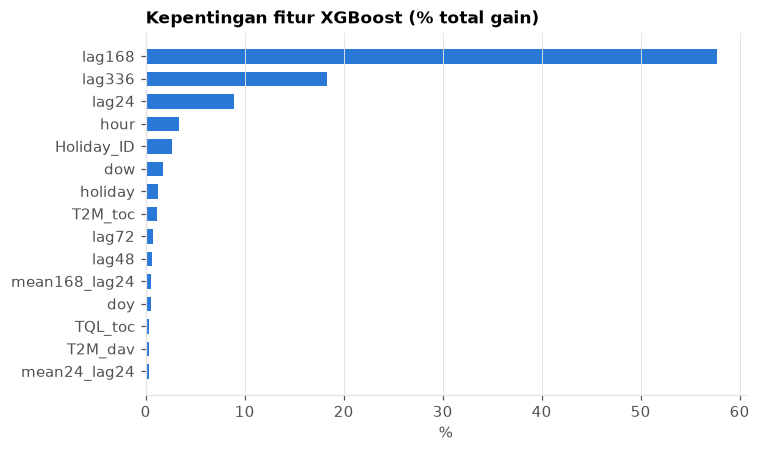

In [19]:
# Kepentingan fitur XGBoost (total gain), 15 teratas
imp = pd.Series(xgbm.get_booster().get_score(importance_type='total_gain')).sort_values()
imp = (imp / imp.sum() * 100).tail(15)
fig, ax = plt.subplots(figsize=(7, 4.2))
ax.barh(imp.index, imp.values, color='#2a78d6', height=0.65)
ax.set(title='Kepentingan fitur XGBoost (% total gain)', xlabel='%'); ax.grid(axis='y', visible=False)
plt.tight_layout(); plt.show()


**Model 5 sampai 8: *Foundation model*.** Bobot model diunduh sekali dari Hugging Face ke folder `models/` lalu selalu dimuat dari folder lokal. Pada pemanggilan berikutnya notebook tidak lagi memerlukan internet. Jumlah parameter dan waktu inferensi dicatat untuk membandingkan biaya komputasi.


In [20]:
# Bobot foundation model diunduh sekali ke folder models/, selanjutnya selalu dimuat dari lokal
def local_model(repo):
    path = MODEL_DIR / repo.split('/')[-1]
    if not (path / 'config.json').exists():
        snapshot_download(repo, local_dir=path, allow_patterns=['*.json', '*.safetensors'])
    return path

n_params = lambda m: sum(p.numel() for p in m.parameters()) / 1e6
ctx_list = [torch.tensor(yv[p - CTX + 1:p + 1]) for p in pos]

In [21]:
# Model 5: Chronos-Bolt (small), zero-shot univariat
bolt = BaseChronosPipeline.from_pretrained(local_model('amazon/chronos-bolt-small'), device_map='cpu')
t0 = time.time()
q, mu = bolt.predict_quantiles(ctx_list, prediction_length=H, quantile_levels=QS)
FC['Chronos-Bolt'] = {'mean': mu.numpy(), 'q': np.sort(q.numpy(), axis=-1)}
INFO['Chronos-Bolt'] = {'jenis': 'Foundation model (zero-shot)', 'parameter_juta': n_params(bolt.model), 'detik_inferensi': time.time() - t0}
print(INFO['Chronos-Bolt'])

{'jenis': 'Foundation model (zero-shot)', 'parameter_juta': 47.718016, 'detik_inferensi': 12.68004035949707}


In [22]:
# Model 6: Chronos-2, zero-shot univariat
c2 = BaseChronosPipeline.from_pretrained(local_model('amazon/chronos-2'), device_map='cpu')
t0 = time.time()
q, mu = c2.predict_quantiles(ctx_list, prediction_length=H, quantile_levels=QS)
FC['Chronos-2'] = {'mean': torch.stack(mu).squeeze(1).numpy(), 'q': np.sort(torch.stack(q).squeeze(1).numpy(), axis=-1)}
INFO['Chronos-2'] = {'jenis': 'Foundation model (zero-shot)', 'parameter_juta': n_params(c2.model), 'detik_inferensi': time.time() - t0}
print(INFO['Chronos-2'])

{'jenis': 'Foundation model (zero-shot)', 'parameter_juta': 119.477664, 'detik_inferensi': 38.62837362289429}


In [23]:
# Model 7: Chronos-2 dengan kovariat masa lalu dan masa depan (suhu tiga kota, kelembapan, kalender)
KOV = ['T2M_toc', 'T2M_san', 'T2M_dav', 'QV2M_toc', 'holiday', 'school']
kv = df[KOV].to_numpy(dtype='float32')
inputs = [{'target': yv[p - CTX + 1:p + 1],
           'past_covariates': {c: kv[p - CTX + 1:p + 1, i] for i, c in enumerate(KOV)},
           'future_covariates': {c: kv[p + 1:p + 1 + H, i] for i, c in enumerate(KOV)}} for p in pos]
t0 = time.time()
q, mu = c2.predict_quantiles(inputs, prediction_length=H, quantile_levels=QS)
FC['Chronos-2+Kov'] = {'mean': torch.stack(mu).squeeze(1).numpy(), 'q': np.sort(torch.stack(q).squeeze(1).numpy(), axis=-1)}
INFO['Chronos-2+Kov'] = {'jenis': 'Foundation model (zero-shot + kovariat)', 'parameter_juta': n_params(c2.model), 'detik_inferensi': time.time() - t0}
print(INFO['Chronos-2+Kov'])

{'jenis': 'Foundation model (zero-shot + kovariat)', 'parameter_juta': 119.477664, 'detik_inferensi': 290.7920763492584}


In [24]:
# Model 8: TimesFM 2.0 (500M), zero-shot univariat; keluaran berisi rata-rata dan kuantil 0,1-0,9
del bolt, c2
tfm = TimesFmModelForPrediction.from_pretrained(local_model('google/timesfm-2.0-500m-pytorch')).eval()
mus, qs = [], []
t0 = time.time()
with torch.no_grad():
    for i in range(0, len(ctx_list), 16):
        o = tfm(past_values=ctx_list[i:i + 16], freq=[0] * len(ctx_list[i:i + 16]), return_dict=True)
        mus.append(o.mean_predictions[:, :H]); qs.append(o.full_predictions[:, :H, 1:])
FC['TimesFM-2.0'] = {'mean': torch.cat(mus).numpy(), 'q': np.sort(torch.cat(qs).numpy(), axis=-1)}
INFO['TimesFM-2.0'] = {'jenis': 'Foundation model (zero-shot)', 'parameter_juta': n_params(tfm), 'detik_inferensi': time.time() - t0}
del tfm
print(INFO['TimesFM-2.0'])

{'jenis': 'Foundation model (zero-shot)', 'parameter_juta': 498.82896, 'detik_inferensi': 105.08906579017639}



## 4. Hasil

Seluruh ramalan disatukan dalam satu tabel panjang (satu baris per origin x jam x model) dan disimpan ke `outputs/forecast_backtest.csv` agar analisis lanjutan maupun dashboard tidak perlu menjalankan ulang model.


In [25]:
# Menyusun seluruh hasil backtest ke format panjang dan menyimpannya ke outputs/
QCOLS = [f'q{q}' for q in QS]
ts = np.stack([y.index[p + 1:p + 1 + H] for p in pos])
base = pd.DataFrame({'origin': np.repeat(origins, H), 'ts': ts.ravel(), 'h': np.tile(np.arange(1, H + 1), len(pos)),
                     'regime': np.repeat(regime, H), 'actual': Y_true.ravel()})
parts = []
for name in MODELS:
    d = base.assign(model=name, mean=FC[name]['mean'].ravel())
    if FC[name]['q'] is not None:
        d = d.assign(**{c: FC[name]['q'][..., j].ravel() for j, c in enumerate(QCOLS)})
    parts.append(d)
fc_long = pd.concat(parts, ignore_index=True)
fc_long.to_csv(OUT / 'forecast_backtest.csv', index=False)
print(fc_long.shape); fc_long.head()

(34176, 16)


,origin,ts,h,regime,actual,model,mean,q0.1,q0.2,q0.3,q0.4,q0.5,q0.6,q0.7,q0.8,q0.9
0,2020-01-01,2020-01-01 01:00:00,1,Normal,1017.580627,Chronos-2+Kov,1015.939453,995.284241,1002.500916,1007.485718,1011.285889,1015.939453,1019.636658,1025.419189,1031.318726,1041.471680
1,2020-01-01,2020-01-01 02:00:00,2,Normal,1000.279724,Chronos-2+Kov,999.210938,976.665222,984.183594,990.148926,994.475342,999.210938,1002.397827,1006.555786,1011.926147,1020.628296
2,2020-01-01,2020-01-01 03:00:00,3,Normal,987.238281,Chronos-2+Kov,975.185120,954.328247,961.130554,966.500244,971.175903,975.185120,978.933960,985.687195,995.675293,1007.715454
3,2020-01-01,2020-01-01 04:00:00,4,Normal,970.366699,Chronos-2+Kov,957.052307,931.803406,939.713318,946.359863,952.407715,957.052307,964.183350,971.174072,982.019287,993.408325
4,2020-01-01,2020-01-01 05:00:00,5,Normal,957.676697,Chronos-2+Kov,950.931824,918.758667,929.319946,938.218140,945.247192,950.931824,957.609619,965.446289,976.907959,991.013184


In [26]:
# Metrik titik (MAE, RMSE, MAPE, MASE) dan probabilistik (WQL, cakupan interval 80%) per model
def metrik(g):
    e = g['actual'] - g['mean']
    out = {'MAE': e.abs().mean(), 'RMSE': np.sqrt((e ** 2).mean()), 'MAPE (%)': (e.abs() / g['actual']).mean() * 100,
           'MASE': e.abs().mean() / MASE_SCALE, 'WQL': np.nan, 'Cakupan 80% (%)': np.nan}
    if g[QCOLS[0]].notna().all():
        yq, Q, tau = g['actual'].to_numpy()[:, None], g[QCOLS].to_numpy(), np.array(QS)
        out['WQL'] = (2 * np.maximum(tau * (yq - Q), (tau - 1) * (yq - Q)).sum(axis=0) / np.abs(yq).sum()).mean()
        out['Cakupan 80% (%)'] = ((yq[:, 0] >= Q[:, 0]) & (yq[:, 0] <= Q[:, -1])).mean() * 100
    return pd.Series(out)

overall = fc_long.groupby('model')[['actual', 'mean'] + QCOLS].apply(metrik).sort_values('MAE')
overall['Skill vs SNaive (%)'] = (1 - overall['MAE'] / overall.loc['SNaive-168', 'MAE']) * 100
overall.to_csv(OUT / 'metrik_keseluruhan.csv')
overall.round(3)

,MAE,RMSE,MAPE (%),MASE,WQL,Cakupan 80% (%),Skill vs SNaive (%)
model,,,,,,,
Chronos-2+Kov,32.891,48.005,2.793,0.564,0.022,74.485,54.099
Chronos-2,33.495,50.939,2.854,0.574,0.023,74.930,53.257
Chronos-Bolt,37.253,56.259,3.182,0.638,0.025,80.009,48.012
TimesFM-2.0,37.976,56.580,3.221,0.651,0.026,74.953,47.003
XGBoost,48.605,69.858,4.186,0.833,NaN,NaN,32.169
SARIMAX-W,53.111,80.860,4.440,0.910,0.038,87.430,25.882
SNaive-168,71.657,100.106,6.112,1.228,NaN,NaN,0.000
SARIMAX-DHR,102.237,142.880,9.024,1.752,0.071,75.281,-42.676


In [27]:
# Metrik menurut regime: Normal (Jan s.d. 14 Mar 2020) vs COVID-19 (15 Mar s.d. 26 Jun 2020)
by_reg = fc_long.groupby(['regime', 'model'])[['actual', 'mean'] + QCOLS].apply(metrik)
by_reg.to_csv(OUT / 'metrik_per_regime.csv')
by_reg[['MAE', 'MAPE (%)', 'MASE', 'WQL', 'Cakupan 80% (%)']].unstack(0).swaplevel(axis=1).sort_index(axis=1).loc[overall.index].round(3)

regime               COVID-19                                          Normal  \
              Cakupan 80% (%)      MAE MAPE (%)   MASE    WQL Cakupan 80% (%)   
model                                                                           
Chronos-2+Kov          72.396   30.724    2.772  0.526  0.022          77.421   
Chronos-2              72.436   32.758    2.939  0.561  0.024          78.435   
Chronos-Bolt           76.643   35.684    3.217  0.611  0.026          84.741   
TimesFM-2.0            69.792   36.606    3.274  0.627  0.026          82.207   
XGBoost                   NaN   49.572    4.533  0.849    NaN             NaN   
SARIMAX-W              89.503   47.467    4.237  0.813  0.036          84.516   
SNaive-168                NaN   61.818    5.627  1.059    NaN             NaN   
SARIMAX-DHR            64.543  128.529   11.792  2.202  0.095          90.372   

regime                                        
                  MAE MAPE (%)   MASE    WQL  
model                                         
Chronos-2+Kov  35.937    2.822  0.616  0.022  
Chronos-2      34.529    2.735  0.592  0.022  
Chronos-Bolt   39.457    3.134  0.676  0.025  
TimesFM-2.0    39.901    3.146  0.684  0.025  
XGBoost        47.247    3.699  0.809    NaN  
SARIMAX-W      61.042    4.726  1.046  0.040  
SNaive-168     85.484    6.794  1.465    NaN  
SARIMAX-DHR    65.288    5.133  1.119  0.042


### 4.1 Akurasi keseluruhan

Berdasarkan 4.272 pasangan ramalan-aktual per model, urutan akurasi menurut MAPE adalah sebagai berikut.

| Peringkat | Model | MAE (MWh) | MAPE (%) | MASE | WQL | Cakupan 80% (%) |
|---|---|---|---|---|---|---|
| 1 | Chronos-2+Kov | 32,89 | 2,79 | 0,564 | 0,022 | 74,5 |
| 2 | Chronos-2 | 33,49 | 2,85 | 0,574 | 0,023 | 74,9 |
| 3 | Chronos-Bolt | 37,25 | 3,18 | 0,638 | 0,025 | 80,0 |
| 4 | TimesFM-2.0 | 37,98 | 3,22 | 0,651 | 0,026 | 75,0 |
| 5 | XGBoost | 48,61 | 4,19 | 0,833 | - | - |
| 6 | SARIMAX-W | 53,11 | 4,44 | 0,910 | 0,038 | 87,4 |
| 7 | SNaive-168 | 71,66 | 6,11 | 1,228 | - | - |
| 8 | SARIMAX-DHR | 102,24 | 9,02 | 1,752 | 0,071 | 75,3 |

Ada tiga hasil pokok.

1. **Peringkat atas.** Empat peringkat teratas ditempati *foundation model*. Chronos-2 dengan kovariat menurunkan MAE sebesar 54,1% relatif terhadap SNaive-168.
2. **Perbandingan dengan *seasonal naive*.** Semua model kecuali SARIMAX-DHR memiliki MASE di bawah 1, artinya lebih akurat daripada *seasonal naive* mingguan pada skala data latih. SARIMAX-DHR memiliki MAE 42,7% lebih besar daripada SNaive-168.
3. **Akurasi probabilistik.** Menurut WQL, Chronos-2 dengan kovariat paling akurat (0,022) dan SARIMAX-DHR paling buruk (0,071). Cakupan interval 80% yang paling dekat dengan nominal adalah Chronos-Bolt (80,0%). Chronos-2, Chronos-2 dengan kovariat, dan TimesFM berada di kisaran 74,5% sampai 75,0%. Interval SARIMAX-W terlalu lebar (87,4%).

### 4.2 Akurasi menurut regime

| Model | MAPE Normal (%) | MAPE COVID-19 (%) | Perubahan | Cakupan 80% Normal | Cakupan 80% COVID-19 |
|---|---|---|---|---|---|
| Chronos-2+Kov | 2,82 | 2,77 | -0,05 | 77,4 | 72,4 |
| Chronos-2 | 2,74 | 2,94 | +0,20 | 78,4 | 72,4 |
| Chronos-Bolt | 3,13 | 3,22 | +0,08 | 84,7 | 76,6 |
| TimesFM-2.0 | 3,15 | 3,27 | +0,13 | 82,2 | 69,8 |
| XGBoost | 3,70 | 4,53 | +0,83 | - | - |
| SARIMAX-W | 4,73 | 4,24 | -0,49 | 84,5 | 89,5 |
| SNaive-168 | 6,79 | 5,63 | -1,17 | - | - |
| SARIMAX-DHR | 5,13 | 11,79 | +6,66 | 90,4 | 64,5 |

Hasil per regime dapat diringkas sebagai berikut.

- **Regime Normal.** Model terbaik adalah Chronos-2 univariat (MAPE 2,74%).
- **Regime COVID-19.** Model terbaik adalah Chronos-2 dengan kovariat (MAPE 2,77%).
- **Kenaikan MAPE terbesar.** SARIMAX-DHR naik 6,66 poin persentase, diikuti XGBoost dengan kenaikan 0,83 poin persentase.
- **Model yang membaik.** SARIMAX-W dan SNaive-168 justru membaik pada regime COVID-19. Pada regime ini, SARIMAX-W (4,24%) melampaui XGBoost (4,53%).
- **Cakupan interval *foundation model*.** Seluruh *foundation model* mengalami penurunan cakupan interval 80% pada regime COVID-19, ke kisaran 69,8% sampai 76,6%.


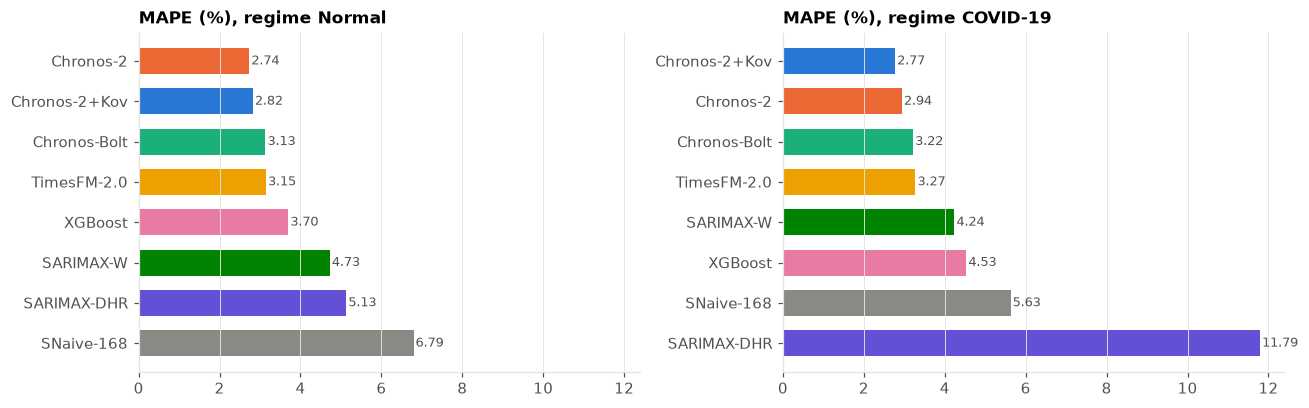

In [28]:
# MAPE per model untuk tiap regime (small multiples, diurutkan dari terbaik)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharex=True)
for ax, reg in zip(axes, ['Normal', 'COVID-19']):
    s = by_reg.loc[reg, 'MAPE (%)'].sort_values(ascending=False)
    ax.barh(s.index, s.values, color=[COLORS[m] for m in s.index], height=0.65)
    for i, v in enumerate(s.values):
        ax.text(v + 0.05, i, f'{v:.2f}', va='center', color=MUTED, fontsize=8.5)
    ax.set(title=f'MAPE (%), regime {reg}'); ax.grid(axis='y', visible=False)
plt.tight_layout(); plt.show()

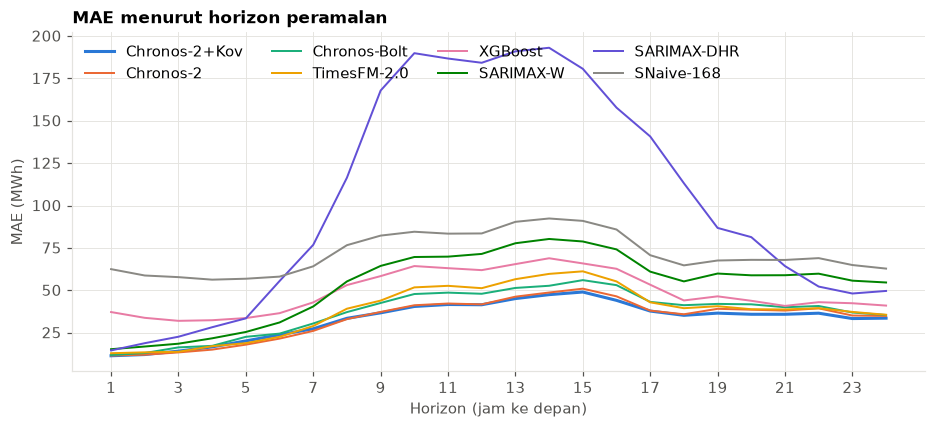

In [29]:
# MAE menurut langkah horizon h = 1..24 jam
hz = fc_long.assign(ae=(fc_long['actual'] - fc_long['mean']).abs()).pivot_table(index='h', columns='model', values='ae', aggfunc='mean')[MODELS]
fig, ax = plt.subplots(figsize=(10, 4))
for mname in MODELS:
    ax.plot(hz.index, hz[mname], color=COLORS[mname], label=mname, lw=2 if mname == overall.index[0] else 1.3)
ax.set(title='MAE menurut horizon peramalan', xlabel='Horizon (jam ke depan)', ylabel='MAE (MWh)', xticks=range(1, 25, 2))
ax.legend(ncol=4, loc='upper left'); plt.show()

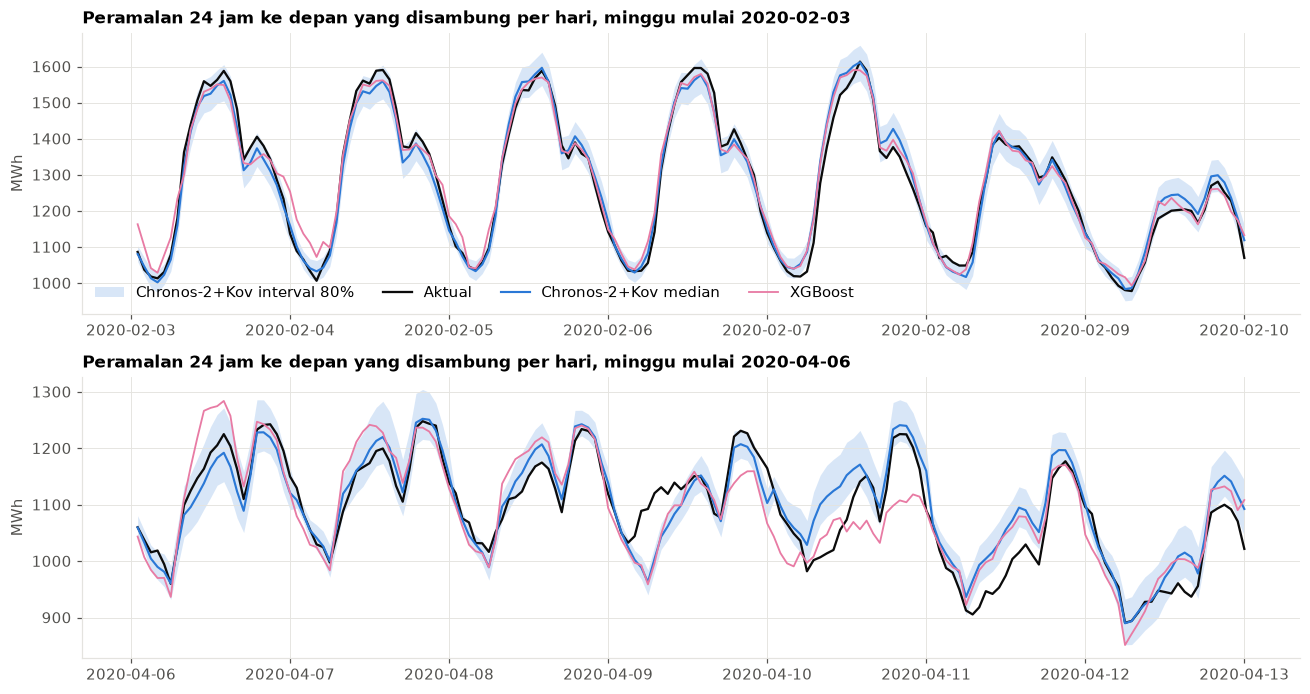

In [30]:
# Contoh peramalan 7 origin berturut-turut di tiap regime: aktual, model terbaik (median + interval 80%), dan XGBoost
best = overall.index[0]
fig, axes = plt.subplots(2, 1, figsize=(12, 6.4))
for ax, start in zip(axes, ['2020-02-03', '2020-04-06']):
    w = fc_long[(fc_long.origin >= start) & (fc_long.origin < pd.Timestamp(start) + pd.Timedelta(days=7))]
    b, x = w[w.model == best], w[w.model == 'XGBoost']
    ax.fill_between(b.ts, b['q0.1'], b['q0.9'], color=COLORS[best], alpha=0.18, lw=0, label=f'{best} interval 80%')
    ax.plot(b.ts, b.actual, color=INK, lw=1.5, label='Aktual')
    ax.plot(b.ts, b['q0.5'], color=COLORS[best], lw=1.4, label=f'{best} median')
    ax.plot(x.ts, x['mean'], color=COLORS['XGBoost'], lw=1.2, label='XGBoost')
    ax.set(title=f'Peramalan 24 jam ke depan yang disambung per hari, minggu mulai {start}', ylabel='MWh')
axes[0].legend(ncol=4, loc='lower left'); plt.tight_layout(); plt.show()


### 4.3 Galat menurut horizon dan contoh ramalan

**Galat menurut horizon.** Karena seluruh origin berada pada pukul 00.00, horizon $h$ sekaligus menunjukkan jam dalam sehari. Pola galat per model adalah sebagai berikut.

- ***Foundation model*.** Rata-rata MAE pada $h = 1$ sampai 6 berkisar 15,2 sampai 17,6 MWh. Galat meningkat hingga mencapai puncak pada $h = 15$ (pukul 15.00), dengan MAE maksimum 49,0 MWh (Chronos-2+Kov) sampai 61,2 MWh (TimesFM), lalu menurun kembali pada malam hari.
- **SARIMAX-W.** Pola galatnya serupa, tetapi dengan puncak lebih tinggi, yaitu 80,3 MWh pada $h = 14$.
- **SARIMAX-DHR.** Model ini mencapai MAE 193,1 MWh pada $h = 14$. Galat ini terkonsentrasi pada jam siang, saat beban paling besar.
- **XGBoost.** Galatnya relatif datar, dari 34,2 MWh pada $h = 1$ sampai 6 menjadi 42,9 MWh pada $h = 19$ sampai 24. Model ini tidak memakai informasi jam-jam terakhir sebelum origin, karena seluruh lag $\geq 24$. Akibatnya, galat XGBoost pada horizon pendek dua kali lipat galat *foundation model*.
- **SNaive-168.** Galatnya hampir tidak bergantung pada horizon (58,4 sampai 66,7 MWh).

**Contoh ramalan.**

- **Minggu 3 sampai 9 Februari 2020 (regime Normal).** Chronos-2 dengan kovariat dan XGBoost memiliki akurasi yang mirip, dengan MAE mingguan 22,1 dan 24,5 MWh.
- **Minggu 6 sampai 12 April 2020 (regime COVID-19, memuat libur Pekan Suci).** Indikator `holiday` bernilai 1 pada 9 sampai 12 April. MAE mingguan Chronos-2 dengan kovariat adalah 28,0 MWh, Chronos-2 29,9 MWh, XGBoost 38,5 MWh, dan SARIMAX-DHR 178,5 MWh. Galat semua model meningkat pada 9 dan 10 April. Pada dua hari tersebut, MAE Chronos-2 dengan kovariat adalah 37,3 dan 38,3 MWh, sedangkan MAE XGBoost 48,1 dan 55,8 MWh.


In [31]:
# Uji Diebold-Mariano dengan varians HAC (Newey-West, lag 5) pada rata-rata galat absolut harian
def dm_test(l1, l2, lag=5):
    d = l1 - l2; n = len(d); db = d.mean()
    g = [np.mean((d[k:] - db) * (d[:n - k] - db)) for k in range(lag + 1)]
    v = g[0] + 2 * sum((1 - k / (lag + 1)) * g[k] for k in range(1, lag + 1))
    s = db / np.sqrt(v / n)
    return s, 2 * stats.t.sf(abs(s), n - 1)

dae = fc_long.assign(ae=(fc_long['actual'] - fc_long['mean']).abs()).pivot_table(index=['origin', 'regime'], columns='model', values='ae', aggfunc='mean')
pairs = [(best, m) for m in MODELS if m != best] + ([('Chronos-2+Kov', 'Chronos-2')] if best not in ('Chronos-2+Kov', 'Chronos-2') else [])
rows = []
for a, b_ in pairs:
    for reg, sub in [('Semua', dae), ('Normal', dae.xs('Normal', level='regime')), ('COVID-19', dae.xs('COVID-19', level='regime'))]:
        s, p = dm_test(sub[a].to_numpy(), sub[b_].to_numpy())
        rows.append({'Model A': a, 'Model B': b_, 'Regime': reg, 'Selisih MAE (A-B)': (sub[a] - sub[b_]).mean(), 'DM': s, 'p-value': p})
dm = pd.DataFrame(rows)
dm['Kesimpulan (alpha 5%)'] = np.where(dm['p-value'] < 0.05, np.where(dm['DM'] < 0, 'A lebih akurat', 'B lebih akurat'), 'Tidak berbeda signifikan')
dm.to_csv(OUT / 'uji_diebold_mariano.csv', index=False)
dm.round(4)

,Model A,Model B,Regime,Selisih MAE (A-B),DM,p-value,Kesimpulan (alpha 5%)
0,Chronos-2+Kov,Chronos-2,Semua,-0.6035,-0.6276,0.5311,Tidak berbeda signifikan
1,Chronos-2+Kov,Chronos-2,Normal,1.4071,0.7821,0.4367,Tidak berbeda signifikan
2,Chronos-2+Kov,Chronos-2,COVID-19,-2.0342,-2.1648,0.0327,A lebih akurat
3,Chronos-2+Kov,Chronos-Bolt,Semua,-4.3616,-2.9550,0.0036,A lebih akurat
4,Chronos-2+Kov,Chronos-Bolt,Normal,-3.5201,-1.2335,0.2214,Tidak berbeda signifikan
5,Chronos-2+Kov,Chronos-Bolt,COVID-19,-4.9603,-3.3567,0.0011,A lebih akurat
6,Chronos-2+Kov,TimesFM-2.0,Semua,-5.0847,-3.2191,0.0015,A lebih akurat
7,Chronos-2+Kov,TimesFM-2.0,Normal,-3.9649,-1.6308,0.1072,Tidak berbeda signifikan
8,Chronos-2+Kov,TimesFM-2.0,COVID-19,-5.8814,-2.8270,0.0056,A lebih akurat
9,Chronos-2+Kov,XGBoost,Semua,-15.7142,-3.5120,0.0006,A lebih akurat



### 4.4 Uji Diebold-Mariano

Model A dalam setiap pasangan adalah Chronos-2+Kov, yaitu model dengan MAE keseluruhan terendah.

| Model B | Semua (selisih MAE; *p*) | Normal (selisih MAE; *p*) | COVID-19 (selisih MAE; *p*) |
|---|---|---|---|
| Chronos-2 | -0,60; 0,531 | +1,41; 0,437 | -2,03; **0,033** |
| Chronos-Bolt | -4,36; **0,004** | -3,52; 0,221 | -4,96; **0,001** |
| TimesFM-2.0 | -5,08; **0,002** | -3,96; 0,107 | -5,88; **0,006** |
| XGBoost | -15,71; **< 0,001** | -11,31; 0,074 | -18,85; **0,003** |
| SARIMAX-W | -20,22; **< 0,001** | -25,11; **< 0,001** | -16,74; **< 0,001** |
| SARIMAX-DHR | -69,35; **< 0,001** | -29,35; **< 0,001** | -97,80; **< 0,001** |
| SNaive-168 | -38,77; **< 0,001** | -49,55; **< 0,001** | -31,09; **< 0,001** |

Selisih MAE dinyatakan dalam MWh, dan nilai *p* yang dicetak tebal signifikan pada $\alpha = 5\%$. Hasil uji dapat diringkas sebagai berikut.

- **Keseluruhan periode.** Chronos-2+Kov signifikan lebih akurat daripada semua model kecuali Chronos-2 univariat.
- **Regime Normal (74 hari).** Keunggulan atas Chronos-Bolt, TimesFM, dan XGBoost tidak signifikan, sedangkan keunggulan atas model statistik tetap signifikan.
- **Regime COVID-19 (104 hari).** Seluruh selisih signifikan, termasuk terhadap Chronos-2 univariat.


In [32]:
# Ringkasan efisiensi komputasi tiap model
pd.DataFrame(INFO).T.loc[MODELS].round(2)

,jenis,parameter_juta,detik_inferensi,detik_latih
Chronos-2+Kov,Foundation model (zero-shot + kovariat),119.477664,290.792076,NaN
Chronos-2,Foundation model (zero-shot),119.477664,38.628374,NaN
Chronos-Bolt,Foundation model (zero-shot),47.718016,12.68004,NaN
TimesFM-2.0,Foundation model (zero-shot),498.82896,105.089066,NaN
XGBoost,Machine learning (gradient boosting),NaN,NaN,3.155801
SARIMAX-W,Statistik (beda musiman + ARIMA),0.00001,NaN,NaN
SARIMAX-DHR,Statistik (regresi + ARIMA),0.000029,3.411613,NaN
SNaive-168,Baseline statistik,0,NaN,NaN



## 5. Penyimpanan dan pemuatan ulang model

Semua model disimpan di folder `models/`:

| Berkas | Isi | Cara memuat |
|---|---|---|
| `xgb_beban.json` | Model XGBoost | `m = xgb.XGBRegressor(); m.load_model('models/xgb_beban.json')` |
| `sarimax_dhr.pkl` | Hasil estimasi SARIMAX-DHR | `SARIMAXResults.load('models/sarimax_dhr.pkl')` |
| `sarimax_w.pkl` | Parameter dan spesifikasi SARIMAX-W (versi ringan, sekitar 1 MB, tanpa matriks *smoother* dan tanpa data latih) | `SARIMAXResults.load('models/sarimax_w.pkl').apply(z_baru, exog=X_baru)` |
| `chronos-bolt-small/` | Bobot Chronos-Bolt | `BaseChronosPipeline.from_pretrained('models/chronos-bolt-small')` |
| `chronos-2/` | Bobot Chronos-2 | `BaseChronosPipeline.from_pretrained('models/chronos-2')` |
| `timesfm-2.0-500m-pytorch/` | Bobot TimesFM 2.0 | `TimesFmModelForPrediction.from_pretrained('models/timesfm-2.0-500m-pytorch')` |

Sel berikut memverifikasi bahwa model XGBoost, SARIMAX-DHR, dan SARIMAX-W yang dimuat ulang menghasilkan prediksi identik dengan hasil *backtest* (pemeriksaan `assert`), lalu memakai Chronos-2 dari folder lokal untuk meramal 24 jam setelah akhir data. Ramalan masa depan memakai Chronos-2 univariat karena nilai cuaca setelah 27 Juni 2020 tidak tersedia dalam dataset.


In [33]:
# Verifikasi model tersimpan: memuat ulang XGBoost dan SARIMAX lalu memastikan prediksinya identik dengan backtest
xgb_load = xgb.XGBRegressor(); xgb_load.load_model(MODEL_DIR / 'xgb_beban.json')
sar_load, sarw_load = SARIMAXResults.load(MODEL_DIR / 'sarimax_dhr.pkl'), SARIMAXResults.load(MODEL_DIR / 'sarimax_w.pkl')
p = pos[-1]
f_sar = sar_load.apply(y.iloc[p - W + 1:p + 1], exog=X_dhr.iloc[p - W + 1:p + 1]).forecast(H, exog=X_dhr.iloc[p + 1:p + 1 + H])
assert np.allclose(xgb_load.predict(F.iloc[tgt]).reshape(len(pos), H), FC['XGBoost']['mean'], atol=1e-3)
f_w = yv[p + 1 - 168:p + 1 - 168 + H] + sarw_load.apply(zw.iloc[p - W + 1:p + 1], exog=Xw.iloc[p - W + 1:p + 1]).forecast(H, exog=Xw.iloc[p + 1:p + 1 + H]).to_numpy()
assert np.allclose(f_sar.to_numpy(), FC['SARIMAX-DHR']['mean'][-1], atol=1e-6)
assert np.allclose(f_w, FC['SARIMAX-W']['mean'][-1], atol=1e-4)
print('Model tersimpan identik dengan hasil backtest. Isi folder models/:')
for f in sorted(MODEL_DIR.iterdir()):
    size = sum(x.stat().st_size for x in f.rglob('*') if x.is_file()) if f.is_dir() else f.stat().st_size
    print(f'  {f.name:<28} {size / 1e6:8.1f} MB')

Model tersimpan identik dengan hasil backtest. Isi folder models/:
  chronos-2                       477.9 MB
  chronos-bolt-small              190.9 MB
  sarimax_dhr.pkl                  27.6 MB
  sarimax_w.pkl                     1.0 MB
  timesfm-2.0-500m-pytorch       1995.4 MB
  xgb_beban.json                    3.6 MB


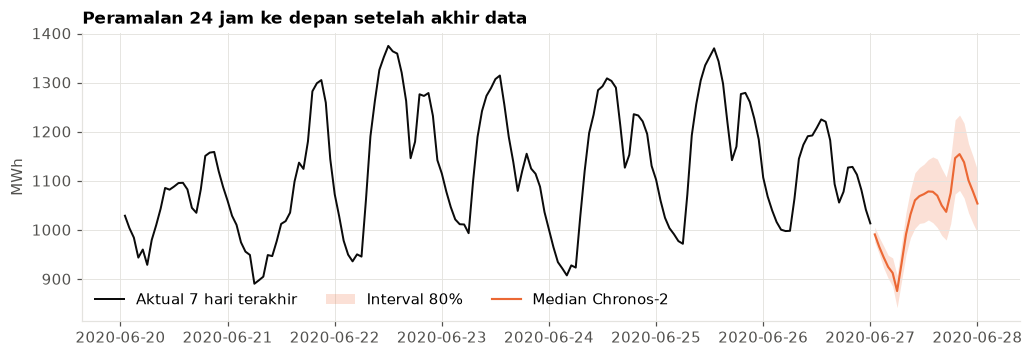

,q0.1,q0.5,q0.9
2020-06-27 01:00:00,975.400024,991.099976,1006.099976
2020-06-27 02:00:00,950.799988,965.900024,985.000000
2020-06-27 03:00:00,922.700012,944.299988,967.400024
2020-06-27 04:00:00,901.700012,924.700012,948.700012
2020-06-27 05:00:00,885.200012,912.700012,943.299988
2020-06-27 06:00:00,841.900024,875.799988,907.400024


In [34]:
# Peramalan nyata 24 jam setelah akhir data (27 Jun 2020) dengan Chronos-2 yang dimuat dari folder lokal
c2_load = BaseChronosPipeline.from_pretrained(MODEL_DIR / 'chronos-2', device_map='cpu')
q, mu = c2_load.predict_quantiles([torch.tensor(yv[-CTX:])], prediction_length=H, quantile_levels=QS)
fut_idx = pd.date_range(y.index[-1] + pd.Timedelta(hours=1), periods=H, freq='h')
future = pd.DataFrame(q[0][0].numpy(), index=fut_idx, columns=QCOLS)[['q0.1', 'q0.5', 'q0.9']]
fig, ax = plt.subplots(figsize=(11, 3.4))
hist = y.iloc[-24 * 7:]
ax.plot(hist.index, hist, color=INK, lw=1.3, label='Aktual 7 hari terakhir')
ax.fill_between(fut_idx, future['q0.1'], future['q0.9'], color=COLORS['Chronos-2'], alpha=0.2, lw=0, label='Interval 80%')
ax.plot(fut_idx, future['q0.5'], color=COLORS['Chronos-2'], label='Median Chronos-2')
ax.set(title='Peramalan 24 jam ke depan setelah akhir data', ylabel='MWh'); ax.legend(loc='lower left', ncol=3); plt.show()
future.to_csv(OUT / 'forecast_masa_depan_24jam.csv'); future.round(1).head(6)

In [35]:
# Ekspor ringkasan hasil ke dashboard/data.js agar dashboard HTML dapat dibuka langsung tanpa server
r1 = lambda a: np.round(np.asarray(a, dtype=float), 1).tolist()
yd_all = y.resample('D').mean()
bt = {'origins': [o.strftime('%Y-%m-%d') for o in origins], 'regime': regime.tolist(), 'actual': r1(Y_true),
      'mean': {m: r1(FC[m]['mean']) for m in MODELS},
      'band': {m: {'lo': r1(FC[m]['q'][..., 0]), 'mid': r1(FC[m]['q'][..., 4]), 'hi': r1(FC[m]['q'][..., -1])} for m in MODELS if FC[m]['q'] is not None}}
clean = lambda d: json.loads(pd.DataFrame(d).to_json(orient='split', double_precision=4))
DATA_OUT = {
    'meta': {'n_obs': len(y), 'start': str(y.index[0]), 'end': str(y.index[-1]), 'n_origin': len(pos), 'H': H, 'CTX': CTX,
             'covid_start': str(COVID_START.date()), 'mase_scale': round(float(MASE_SCALE), 2), 'best': best, 'models': MODELS, 'colors': COLORS},
    'daily': {'dates': [d.strftime('%Y-%m-%d') for d in yd_all.index], 'values': r1(yd_all)},
    'yearly': clean(yr.round(2)), 'profile': {'rows': prof.index.tolist(), 'cols': prof.columns.tolist(), 'z': r1(prof)},
    'holiday_profile': {'hour': hol.index.tolist(), 'biasa': r1(hol[0]), 'libur': r1(hol[1])},
    'corr': clean(corr.round(3)), 'strength': {k: round(max(0, float(v)), 3) for k, v in strength.items()},
    'overall': clean(overall), 'by_regime': clean(by_reg.reset_index()), 'horizon': {m: r1(hz[m]) for m in MODELS},
    'dm': clean(dm), 'info': clean(pd.DataFrame(INFO).T.loc[MODELS]), 'importance': {'f': imp.index.tolist(), 'v': r1(imp)},
    'future': {'ts': [t.strftime('%Y-%m-%d %H:%M') for t in fut_idx], 'lo': r1(future['q0.1']), 'mid': r1(future['q0.5']), 'hi': r1(future['q0.9']),
               'hist_ts': [t.strftime('%Y-%m-%d %H:%M') for t in hist.index], 'hist': r1(hist)},
    'backtest': bt}
(DASH / 'data.js').write_text('window.DATA = ' + json.dumps(DATA_OUT, separators=(',', ':')) + ';', encoding='utf-8')
print(f"dashboard/data.js: {(DASH / 'data.js').stat().st_size / 1e6:.2f} MB")

dashboard/data.js: 0.86 MB



## 6. Pembahasan

### 6.1 Mengapa *foundation model* unggul atas model yang dibangun dengan pengetahuan domain

Keempat konfigurasi *foundation model* menempati empat peringkat teratas, padahal tidak satu pun parameternya diestimasi pada data Panama. Tiga mekanisme diduga menjelaskan temuan ini.

1. **Konteks panjang sebagai pengganti estimasi.** Konteks 2.048 jam (sekitar 12 minggu) memuat lebih dari dua belas siklus mingguan dan sekitar 85 siklus harian. Dengan konteks sepanjang itu, model dapat membaca bentuk musiman ganda, level terkini, dan variasi antarminggu langsung dari data terbaru. Pada model statistik, struktur yang sama harus dispesifikasikan secara eksplisit oleh analis, misalnya orde ARIMA atau jumlah harmonik Fourier. Kesalahan spesifikasi pada tahap ini langsung menjadi galat ramalan.
2. **Adaptasi tanpa pelatihan ulang.** Setiap origin memberi konteks baru, sehingga *foundation model* secara otomatis menyesuaikan diri dengan level beban yang baru setelah pembatasan COVID-19. Sebaliknya, XGBoost, SARIMAX-W, dan SARIMAX-DHR memakai parameter hasil estimasi 2019 yang tidak diperbarui selama periode uji. Sebagian keunggulan *foundation model* karenanya berasal dari desain evaluasi tanpa pelatihan ulang. Pelatihan ulang bergulir pada model domain dapat mempersempit selisih tersebut, dan hal ini menjadi saran penelitian lanjutan.
3. **Pengetahuan pra-pelatihan.** Pola beban listrik, yaitu musiman harian dan mingguan yang kuat dengan level yang bergeser perlahan, merupakan pola yang lazim pada korpus deret waktu publik. Model yang telah melihat banyak deret sejenis memiliki *prior* yang tepat untuk tipe deret ini. Konsekuensinya, terdapat risiko kontaminasi: jika dataset Panama atau deret beban serupa termasuk dalam korpus pra-pelatihan, akurasi *zero-shot* dapat terlihat lebih baik daripada kinerja pada deret yang benar-benar baru `[RUJUKAN DIPERLUKAN: daftar dataset pra-pelatihan Chronos-2 dan TimesFM 2.0; periksa apakah dataset Panama (Aguilar Madrid, 2021) termasuk]`.

Perbedaan di antara *foundation model* juga informatif. Chronos-2 (119,5 juta parameter) lebih akurat daripada TimesFM 2.0 (498,8 juta parameter) dan Chronos-Bolt (47,7 juta parameter). Jumlah parameter bukan penentu utama akurasi untuk deret ini; arsitektur dan korpus pelatihan lebih berpengaruh. Dari sisi biaya, Chronos-Bolt meramal 178 jendela dalam 12,7 detik di CPU dengan MAPE 3,18%, sehingga menawarkan rasio akurasi terhadap biaya yang paling baik.

### 6.2 Peran kovariat cuaca dan kalender

Penambahan kovariat menurunkan MAE Chronos-2 sebesar 0,60 MWh untuk keseluruhan periode, tetapi selisih ini tidak signifikan ($p = 0{,}53$). Pada regime Normal, kovariat justru sedikit memperburuk akurasi (+1,41 MWh, tidak signifikan). Pada regime COVID-19, kovariat memperbaiki akurasi secara signifikan (−2,03 MWh; $p = 0{,}033$). Pola ini sejalan dengan temuan eksploratif pada Subbab 2.5: dalam kondisi normal, riwayat beban sudah memuat hampir seluruh informasi yang dapat diramalkan. Kovariat baru bernilai ketika riwayat kurang informatif, yaitu setelah perubahan regime.

Kovariat mana yang memberi manfaat? Indikator `school` tetap bernilai 1 sepanjang Maret sampai Juni 2020 karena mengikuti kalender akademik resmi dan tidak mencatat penutupan sekolah akibat COVID-19. Dengan demikian, variabel ini tidak membawa informasi tentang pembatasan. Kandidat yang lebih masuk akal adalah (a) indikator `holiday`, karena April 2020 memuat 96 jam libur nasional yang tidak dapat diantisipasi dari pola minggu sebelumnya, dan (b) suhu, yang naik dari rata-rata 26,96 °C pada Januari menjadi 28,19 °C pada April dan 28,12 °C pada Mei di Tocumen. Atribusi yang pasti memerlukan analisis ablasi per kovariat, yang menjadi saran penelitian lanjutan.

Kovariat cuaca dalam analisis ini adalah nilai observasi, bukan ramalan cuaca, sehingga manfaatnya merupakan batas atas (*oracle*). Dalam operasi nyata, ramalan suhu 24 jam ke depan memiliki galat. Manfaat kovariat suhu karenanya akan lebih kecil, sedangkan manfaat indikator kalender tetap utuh karena kalender diketahui pasti sebelumnya.

### 6.3 Ketangguhan terhadap perubahan struktural COVID-19

Perubahan MAPE dari regime Normal ke regime COVID-19 membedakan model secara tegas.

- ***Foundation model*** relatif stabil: Chronos-2 naik dari 2,74% menjadi 2,94%, Chronos-Bolt dari 3,13% menjadi 3,22%, dan TimesFM dari 3,15% menjadi 3,27%. Chronos-2 dengan kovariat justru membaik dari 2,82% menjadi 2,77%.
- **XGBoost** memburuk dari 3,70% menjadi 4,53% (naik sekitar 23%). Fitur kalender (bulan dan hari ke-) mempelajari hubungan musiman pada level beban sebelum 2020. Setelah level turun 14%, hubungan tersebut menghasilkan bias ke atas yang hanya sebagian dikoreksi oleh fitur lag.
- **SARIMAX-W** membaik dari 4,73% menjadi 4,24% dan pada regime COVID-19 melampaui XGBoost. Pembedaan musiman 168 jam membuat model selalu berangkat dari pola minggu lalu, sehingga pergeseran level dan perubahan bentuk profil harian terserap dalam satu minggu.
- **SNaive-168** juga membaik (dari 6,79% menjadi 5,63%). Dugaannya, regime Normal memuat lebih banyak transisi kalender (Tahun Baru, kembalinya aktivitas awal Januari, dan Karnaval pada Februari) yang membuat pola minggu lalu kurang representatif. Setelah penurunan awal, beban COVID-19 justru relatif datar dari minggu ke minggu.
- **SARIMAX-DHR** gagal paling parah, dari 5,13% menjadi 11,79%. Model ini memakai bentuk musiman deterministik (suku Fourier dengan koefisien tetap dari 2019) dan tidak memiliki interaksi antara pola harian dan pola mingguan. Ketika pembatasan mengubah bentuk profil harian (beban komersial siang hari turun lebih besar daripada beban dini hari), galat ARIMA(2,1,1) hanya mampu mengoreksi level, tidak bentuk. Kasus ini menunjukkan risiko model yang terlalu bergantung pada struktur deterministik yang diestimasi dari satu regime.

Pelajaran metodologisnya: dalam kondisi perubahan struktural, model yang mengkondisikan diri pada data terbaru (*foundation model* melalui konteks, SARIMAX-W melalui pembedaan musiman) lebih tangguh daripada model yang mengandalkan struktur tetap hasil estimasi masa lalu.

### 6.4 Kalibrasi interval prediksi

Pada regime Normal, cakupan interval 80% *foundation model* mendekati nominal: 77,4% untuk Chronos-2 dengan kovariat dan 78,4% untuk Chronos-2. Chronos-Bolt (84,7%) dan TimesFM (82,2%) sedikit terlalu lebar. Pada regime COVID-19, seluruh *foundation model* menghasilkan interval yang terlalu sempit, dengan cakupan 69,8% (TimesFM) sampai 76,6% (Chronos-Bolt). Model mempelajari tingkat ketidakpastian dari konteks yang sebagian besar masih berasal dari periode sebelum perubahan. Akibatnya, ketidakpastian setelah perubahan regime cenderung diremehkan. SARIMAX-DHR menunjukkan pola ekstrem: interval terlalu lebar pada regime Normal (90,4%) dan terlalu sempit pada regime COVID-19 (64,5%), karena varians galatnya tetap dari estimasi 2019. SARIMAX-W menghasilkan interval yang terlalu lebar pada kedua regime (84,5% dan 89,5%), karena $\sigma^2$ hasil estimasi 2019 diduga membesar akibat anomali Januari 2019 dan galat besar di sekitar hari libur. Interval analitik berasumsi Gaussian juga tidak menangkap kesalahan spesifikasi bentuk musiman.

Untuk penggunaan operasional, interval dari *foundation model* sebaiknya dikalibrasi ulang, misalnya dengan *conformal prediction* bergulir yang menyesuaikan lebar interval berdasarkan galat terbaru `[RUJUKAN DIPERLUKAN: metode conformal prediction adaptif untuk deret waktu]`.

### 6.5 Posisi hasil terhadap penelitian terdahulu

Aguilar Madrid dan Antonio (2021) memakai dataset yang sama untuk horizon mingguan (168 jam) dengan model *machine learning*, dengan periode uji sebelum pandemi. Karena horizon, periode uji, dan definisi galat berbeda, angka dalam penelitian ini tidak dapat dibandingkan secara langsung dengan angka mereka. Kesamaannya terletak pada temuan bahwa variabel kalender dan pola musiman merupakan prediktor utama. Penelitian ini menambahkan dua hal: pembanding *foundation model zero-shot* dan pengujian pada periode perubahan struktural. Klaim pengembang bahwa Chronos-2 paling diuntungkan pada tugas yang memiliki kovariat `[verifikasi pada Ansari dkk., 2025]` hanya didukung sebagian oleh data Panama, karena manfaat kovariat signifikan pada regime COVID-19 tetapi tidak pada regime Normal.

### 6.6 Keterbatasan

1. **Kovariat *oracle*.** Cuaca observasi dipakai sebagai kovariat masa depan, sehingga akurasi model berkovariat merupakan batas atas.
2. **Satu deret dan satu negara.** Generalisasi ke sistem lain, misalnya sistem dengan puncak malam hari, memerlukan pengujian tambahan.
3. **Tanpa pelatihan ulang dan tanpa penyetelan hiperparameter.** Pada model domain, keputusan ini membuat perbandingan konservatif bagi model domain.
4. **Kekuatan uji terbatas.** Uji Diebold-Mariano pada regime Normal hanya memakai 74 hari, sehingga beberapa selisih yang cukup besar tidak signifikan.
5. **Kualitas pengukuran variabel kalender.** Indikator `school` tidak mencatat penutupan sekolah tahun 2020.
6. **Model yang tidak dijalankan.** Moirai, Lag-Llama, dan TimeGPT hanya dibahas secara konseptual.
7. **Kemungkinan kontaminasi data pra-pelatihan**, sebagaimana dijelaskan pada Subbab 6.1.



## 7. Kesimpulan dan saran

### 7.1 Kesimpulan

1. **Karakteristik data.** Beban listrik Panama didominasi musiman harian (kekuatan 0,906; puncak sekitar pukul 13.00 dengan rasio puncak terhadap lembah 1,61) dan musiman mingguan (kekuatan 0,712). Tren tahunannya tumbuh 2 sampai 3% per tahun, dan efek hari libur signifikan (sekitar −12,8% pada hari kerja; $p < 0{,}001$). Pembatasan COVID-19 menurunkan beban rata-rata sebesar 14,3%. Hubungan suhu dengan beban pada skala harian lemah ($r \approx 0{,}11$ sampai $0{,}15$) karena variasi suhu antarhari kecil.
2. **Akurasi *foundation model*.** Ketiga *foundation model* yang dijalankan secara *zero-shot* lebih akurat daripada seluruh model statistik dan XGBoost. Chronos-2 univariat mencapai MAPE 2,85%, Chronos-Bolt 3,18%, dan TimesFM 2.0 3,22%. Sebagai pembanding, XGBoost mencapai 4,19%, SARIMAX-W 4,44%, SNaive-168 6,11%, dan SARIMAX-DHR 9,02%.
3. **Manfaat kovariat.** Kovariat cuaca dan kalender menjadikan Chronos-2 model terbaik (MAPE 2,79%). Manfaatnya terhadap Chronos-2 univariat hanya signifikan pada regime COVID-19 ($p = 0{,}033$).
4. **Ketangguhan terhadap COVID-19.** *Foundation model* dan SARIMAX-W tetap stabil setelah perubahan struktural. XGBoost memburuk sekitar 23%, dan SARIMAX-DHR gagal (MAPE 11,79%) karena bentuk musiman deterministiknya tidak lagi sesuai.
5. **Signifikansi.** Keunggulan Chronos-2 dengan kovariat atas Chronos-Bolt, TimesFM, XGBoost, SARIMAX-W, SARIMAX-DHR, dan SNaive-168 signifikan untuk keseluruhan periode ($p < 0{,}01$). Selisihnya terhadap Chronos-2 univariat tidak signifikan untuk keseluruhan periode.

### 7.2 Saran

1. **Bagi praktik peramalan**, Chronos-2 (dengan kovariat kalender) dapat dijadikan acuan awal yang wajib dikalahkan sebelum model baru diadopsi. Interval prediksinya perlu dikalibrasi ulang, misalnya dengan *conformal prediction* bergulir.
2. **Bagi penelitian lanjutan:**
   - (a) Mengulang perbandingan dengan ramalan cuaca, bukan cuaca observasi.
   - (b) Menerapkan pelatihan ulang bergulir pada XGBoost dan SARIMAX-W agar perbandingannya setara dalam hal pemakaian data terbaru.
   - (c) Melakukan ablasi per kovariat untuk mengidentifikasi sumber manfaat pada regime COVID-19.
   - (d) Melakukan *fine-tuning* Chronos-2 pada data Panama sebelum 2020.
   - (e) Menjalankan Moirai dan Lag-Llama di lingkungan Python terpisah.
   - (f) Memperluas horizon ke 168 jam agar sebanding dengan Aguilar Madrid dan Antonio (2021).
3. **Bagi kualitas data**, indikator `school` perlu diperbarui agar mencerminkan penutupan sekolah aktual pada 2020.



## Daftar pustaka

Format mengikuti APA edisi ke-7. Seluruh rujukan telah dicek keberadaannya (judul, penulis, tahun, dan pengenal arXiv/DOI) melalui pencarian pada sesi penyusunan notebook ini.

- Aguilar Madrid, E., & Antonio, N. (2021). Short-term electricity load forecasting with machine learning. *Information, 12*(2), 50. https://doi.org/10.3390/info12020050
- Aguilar Madrid, E. `[verifikasi daftar pengunggah]` (2021). *Short-term electricity load forecasting (Panama case study)* [Data set]. Mendeley Data. https://doi.org/10.17632/byx7sztj59.1
- Ansari, A. F., dkk. (2024). Chronos: Learning the language of time series. *arXiv*. https://arxiv.org/abs/2403.07815
- Ansari, A. F., dkk. (2025). Chronos-2: From univariate to universal forecasting. *arXiv*. https://arxiv.org/abs/2510.15821
- Das, A., Kong, W., Sen, R., & Zhou, Y. (2024). A decoder-only foundation model for time-series forecasting. *arXiv*. https://arxiv.org/abs/2310.10688
- Garza, A., Challu, C., & Mergenthaler-Canseco, M. (2023). TimeGPT-1. *arXiv*. https://arxiv.org/abs/2310.03589
- Rasul, K., dkk. (2023). Lag-Llama: Towards foundation models for probabilistic time series forecasting. *arXiv*. https://arxiv.org/abs/2310.08278
- Woo, G., dkk. (2024). Unified training of universal time series forecasting transformers. *arXiv*. https://arxiv.org/abs/2402.02592

Catatan verifikasi: untuk rujukan bertanda "dkk.", pencarian hanya mengonfirmasi judul, pengenal arXiv, dan penulis pertama; daftar penulis lengkap perlu disalin dari halaman arXiv sebelum dipakai di naskah resmi. Rujukan untuk Diebold-Mariano (1995), Newey-West (1987), MSTL, dan regresi harmonik dinamis belum dicantumkan `[RUJUKAN DIPERLUKAN: Diebold & Mariano (1995) Journal of Business & Economic Statistics; Newey & West (1987) Econometrica; Hyndman & Athanasopoulos, Forecasting: Principles and Practice]`.
